In [1]:
%load_ext autoreload
%autoreload 2
# %matplotlib widget
%matplotlib inline

import os
import sys
import torch
import matplotlib
import matplotlib.pyplot as plt

if not '../src' in sys.path:
    sys.path.append('../src')

from dataset import MuonDataset
from models import *
from tools import *
from propagation import *
from scheduler import *
from callbacks import *
from constants import *

In [2]:
def selection(ri,rf,di,df):
    distance_mask =  (ri-rf).norm(dim=-1) > 0.01
    angle = torch.rad2deg(
        torch.acos(
            (di*df).sum(dim=-1)
        )
    )
    angle_mask = torch.logical_and(
        ~torch.isnan(angle),
        angle < 80.,
    )
    mask = torch.logical_and(distance_mask,angle_mask)
    return mask
dataset = MuonDataset.from_data_file(
    data_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/data_obj1.npy',
    momentum_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/momenta_obj1.npy',
    selection = selection,
)

Masking 9021 out of 3844288 events [0.235%]


In [3]:
# surrogate = LossSurrogate(
#     flow = NormalizingFlow(
#         features = dataset.observable_dim,
#         context = dataset.condition_dim,
#         hidden_features = [256,256],
#         transforms = 5,
#         bins = 16,
#     ),
# )
# # surrogate = torch.load('surrogate.pt',weights_only=False,map_location='cpu')
# # print (surrogate)

In [4]:
scheduler = Scheduler(
    dataset = dataset,
    mapper = DenseDensityMapper(
        xlow = dataset.low,
        xhigh = dataset.high,
        ylow = LAMBDA_MIN,
        yhigh = LAMBDA_MAX,
        neurons = [512,512,512,512,512],
        activation = nn.GELU,
        batch_norm = False,
        lr = 1e-3,
    ),
    # mapper = FourierDensityMapper(
    #     # wavelengths = [0.001,0.005,0.01,0.05,0.1,0.5,1.,5.,10.], # m
    #     wavelengths = np.logspace(np.log10(1e-3),np.log10(1e3),100),
    #     gated = True,
    #     xlow = dataset.low,
    #     xhigh = dataset.high,
    #     ylow = LAMBDA_MIN,
    #     yhigh = LAMBDA_MAX,
    #     neurons = [256,256],
    #     activation = nn.GELU,
    #     batch_norm = True,
    #     isotropic = True,
    #     lr = 1e-3,
    # ),
    propagator = RossiPropagator(
        step_size = 0.01, # m
    ),
    # data_surrogate = LossSurrogate(
    #     flow = NormalizingFlow(
    #         features = dataset.observable_dim,
    #         context = dataset.condition_dim,
    #         hidden_features = [256,256],
    #         transforms = 5,
    #         bins = 16,
    #     ),
    # ),
    data_surrogate = torch.load('data_surrogate.pt',weights_only=False,map_location='cpu'),
    sim_surrogate = LossSurrogate(
        flow = NormalizingFlow(
            features = dataset.observable_dim,
            context = dataset.condition_dim,
            hidden_features = [256,256],
            transforms = 5,
            bins = 16,
        ),
    ),
    device = 'cuda:0',
    callbacks = [
        LossPlotCallback(frequency=1),
        MapperPlotCallback(
            low = dataset.low,
            high = dataset.high,
            frequency = 1,
        ),
        ObservablesPlotCallback(frequency=1),
        LogProbPlotCallback(frequency=1),
    ],
)
print (scheduler.mapper)

DenseDensityMapper(
  (mlp): MLP(
    (layers): Sequential(
      (0): Linear(in_features=3, out_features=512, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=512, out_features=512, bias=True)
      (3): GELU(approximate='none')
      (4): Linear(in_features=512, out_features=512, bias=True)
      (5): GELU(approximate='none')
      (6): Linear(in_features=512, out_features=512, bias=True)
      (7): GELU(approximate='none')
      (8): Linear(in_features=512, out_features=512, bias=True)
      (9): GELU(approximate='none')
      (10): Linear(in_features=512, out_features=1, bias=True)
    )
  )
)


In [5]:
# scheduler.train_data_surrogate()

{'Air': 303.9, 'H2': 8.9, 'H2O': 0.361, 'C': 0.193, 'Ca': 0.1042, 'Si': 0.0937, 'Al': 0.08897, 'Fe': 0.01757, 'Cu': 0.01436, 'Pb': 0.005612, 'W': 0.003504, 'U': 0.003166}
Air 0 8.226390259953933e-08
H2 1 2.808988764044944e-06
H2O 2 6.925207756232688e-05
C 3 0.00012953367875647668
Ca 4 0.00023992322456813821
Si 5 0.00026680896478121667
Al 6 0.00028099359334607176
Fe 7 0.001422879908935686
Cu 8 0.0017409470752089138
Pb 9 0.004454739843193158
W 10 0.007134703196347032
U 11 0.007896399241945674


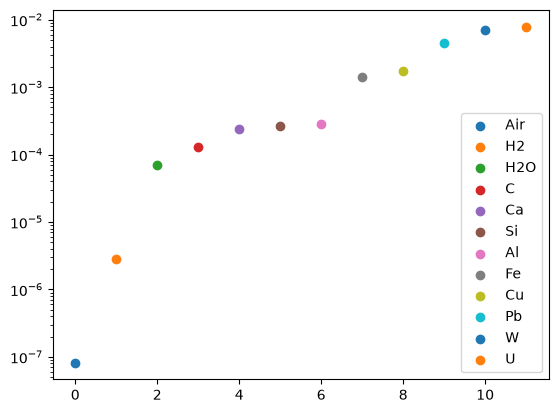

In [6]:
from constants import *
print (X0s)
for i,(name,X0) in enumerate(X0s.items()):
    lam = X0_to_lambda(X0)
    print (name,i,lam)
    plt.scatter(
        i,
        lam,
        label = name,
    )
plt.yscale('log')
plt.legend()
plt.show()

In [7]:
def sampling_function(batch_size):
    low = dataset.low - 10
    high  = dataset.high + 10
    x = low + torch.rand(batch_size,3) * (high-low)
    lam = X0_to_lambda(X0s['Fe'])
    # lam = X0_to_lambda(X0s['Air'])
    return x,lam * torch.ones((batch_size,1))

scheduler.mapper.set_lr(1e-2)
scheduler.pre_train_mapper(
    sampling_function = sampling_function,
    loss_cutoff = 1e-15,
    batch_size = 256,
    max_epochs = 20000,
)
scheduler.mapper.set_lr(1e-3)
scheduler.pre_train_mapper(
    sampling_function = sampling_function,
    loss_cutoff = 1e-16,
    batch_size = 256,
    max_epochs = 10000,
)
scheduler.mapper.set_lr(1e-4)
scheduler.pre_train_mapper(
    sampling_function = sampling_function,
    loss_cutoff = 1e-17,
    batch_size = 256,
    max_epochs = 10000,
)
scheduler.mapper.set_lr(1e-5)
scheduler.pre_train_mapper(
    sampling_function = sampling_function,
    loss_cutoff = 1e-17,
    batch_size = 256,
    max_epochs = 10000,
)

Epoch 1000 : loss = 8.189e-05
Epoch 2000 : loss = 2.308e-05
Epoch 3000 : loss = 4.000e-06
Epoch 4000 : loss = 3.443e-06
Epoch 5000 : loss = 1.762e-05
Epoch 6000 : loss = 6.068e-07
Epoch 7000 : loss = 6.379e-09
Epoch 8000 : loss = 1.086e-09
Epoch 9000 : loss = 1.842e-11
Pre-training stopped after 9221 epochs : loss = 0.000e+00
Pre-training stopped after 170 epochs : loss = 0.000e+00
Pre-training stopped after 1 epochs : loss = 0.000e+00
Pre-training stopped after 2 epochs : loss = 0.000e+00


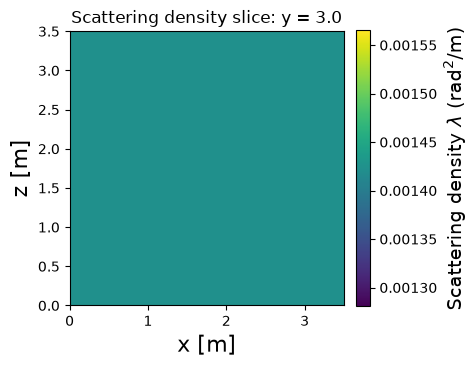

In [8]:
fig = scheduler.mapper.plot_slice(
    direction = 'y',
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
    show_materials = True,
)
plt.show()

Propagation : [====================================================================================================] 100%
Propagation done in 14348 steps, max distance 7.857
Masking 459 out of 10000 events [4.590%]


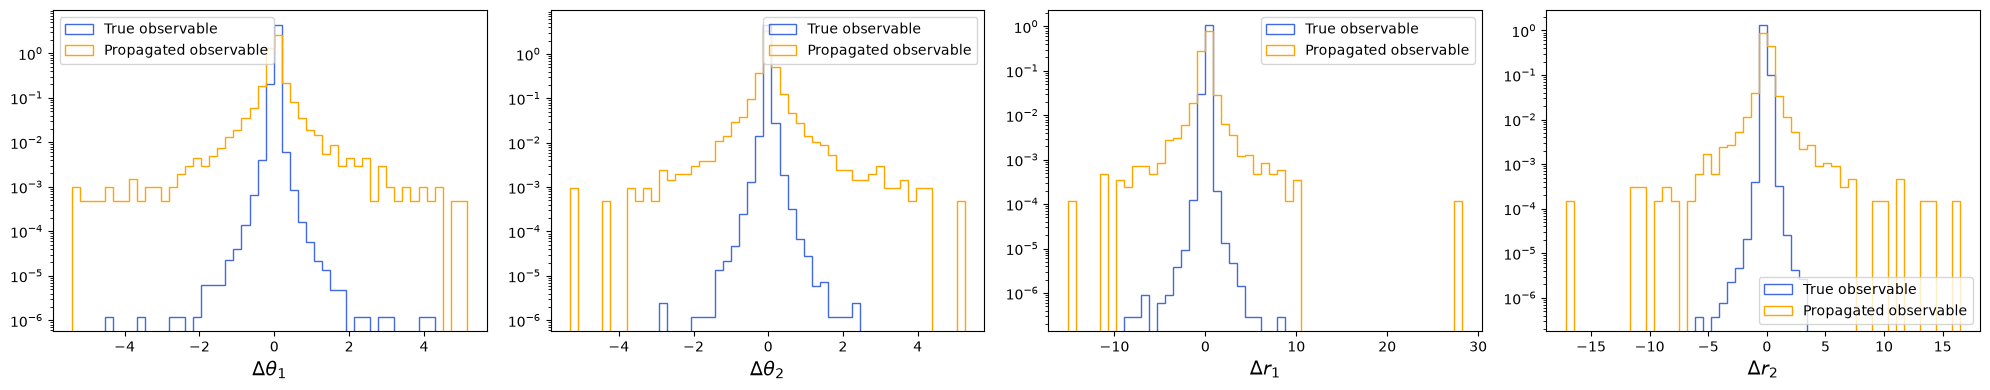

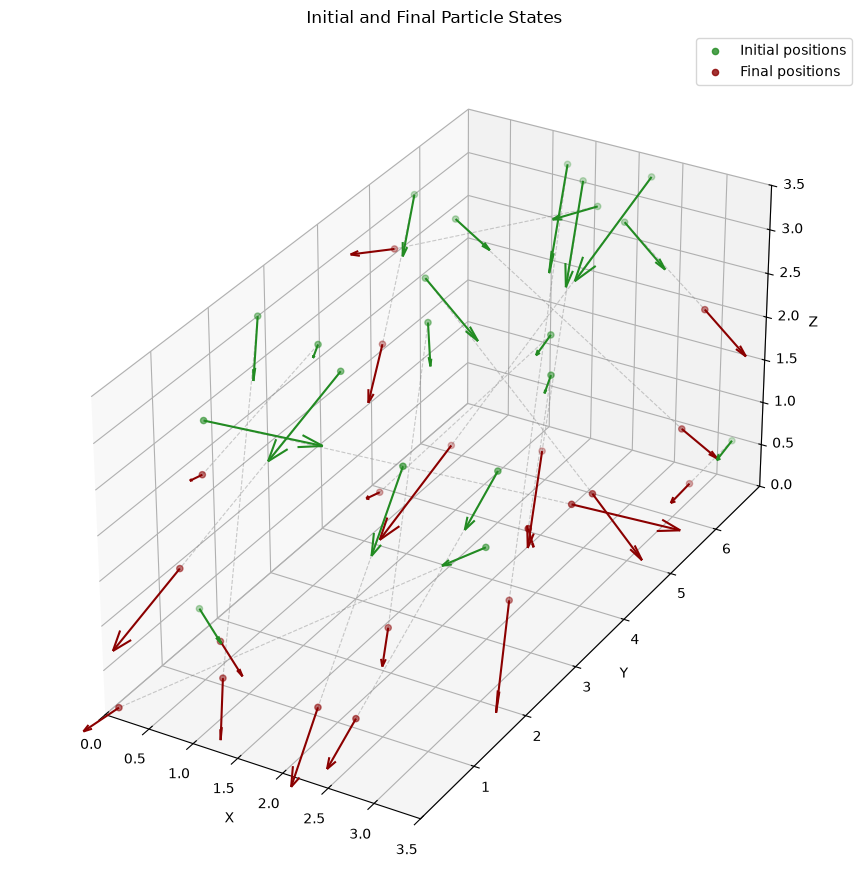

In [9]:
sim_dataset = scheduler.propagate(10000,no_grad=True)


fig = scheduler.callbacks[2].on_observables_end(None,sim_dataset.observables,dataset.observables,dataset.observable_names)
plt.show()

sim_dataset.plot_3d(
    N = 20,
    arrow_scale=0.5,
    show_direction=True,
    show_path=True,                                                                                                                                                                                              
)
plt.show()

In [10]:
# scheduler.initialize(
#     n_epochs = [3,1,1],
#     batch_sizes = [5000,5000,5000],
#     lrs = [1e-3,1e-4,1e-5],
# )

In [13]:
scheduler.mapper.set_lr(1e-3)

Log prob:   0%|          | 0/76 [00:00<?, ?it/s]

Values outside [-5,+5] : 0.020%
Iteration 1/1000 [ 0.10]%
Propagating simulation dataset with 100000 muons
Propagation : [====================================================================================================] 100%
Propagation done in 16111 steps, max distance 7.949
Masking 5985 out of 100000 events [5.985%]


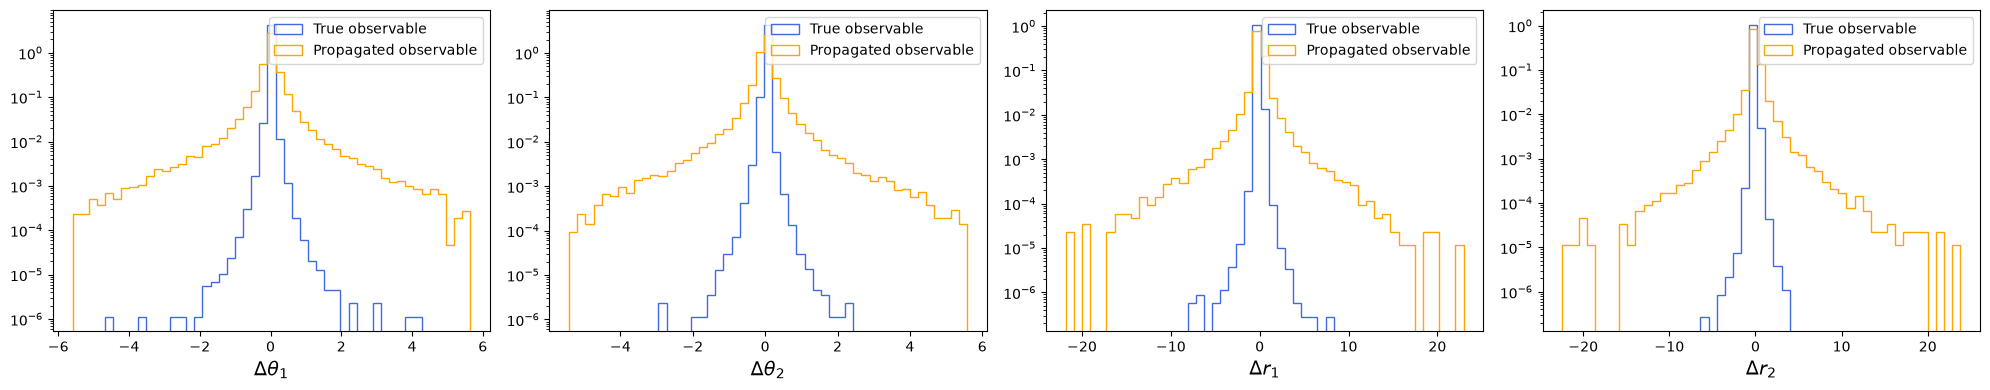

Training simulation surrogate
Epochs = 10 - LR = 1.000e-03 - batch size = 256 - Training set = 84613 [331 batches] - Validation set = 9402 [37 batches]


Training:   0%|          | 0/331 [00:00<?, ?it/s]

Validation:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch:   1/10 - Loss:   -4.529 - Val loss   -4.559


Training:   0%|          | 0/331 [00:00<?, ?it/s]

...

Epoch:   2/3 - Loss:   -4.772 - Val loss   -4.674


Training:   0%|          | 0/331 [00:00<?, ?it/s]

Validation:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch:   3/3 - Loss:   -4.775 - Val loss   -4.672


Validation:   0%|          | 0/2 [00:00<?, ?it/s]

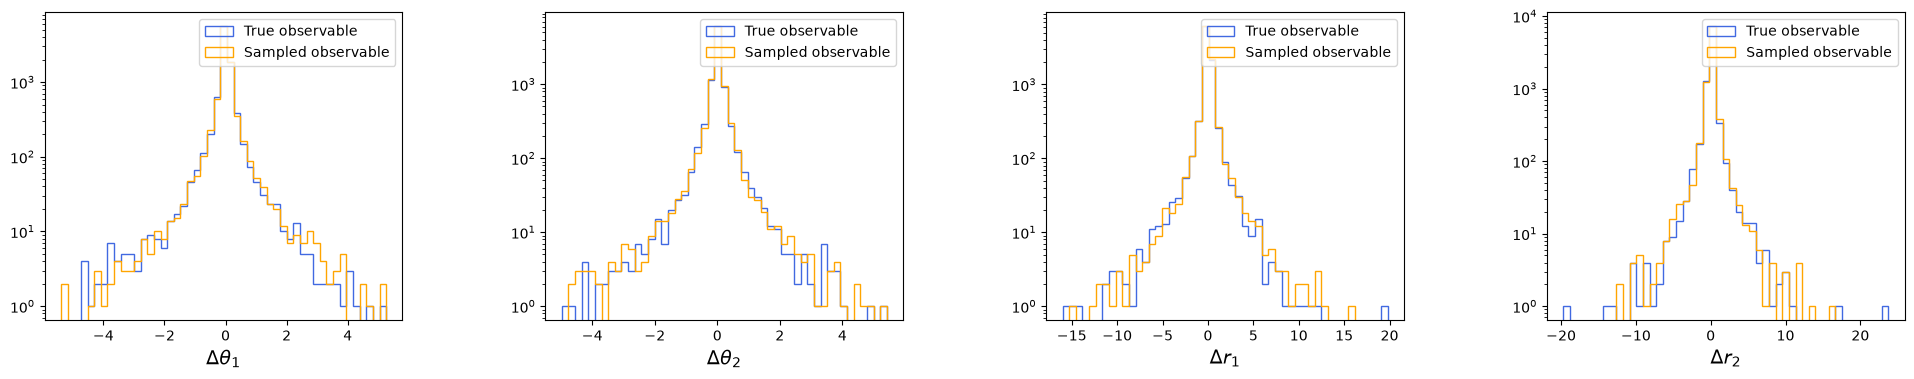

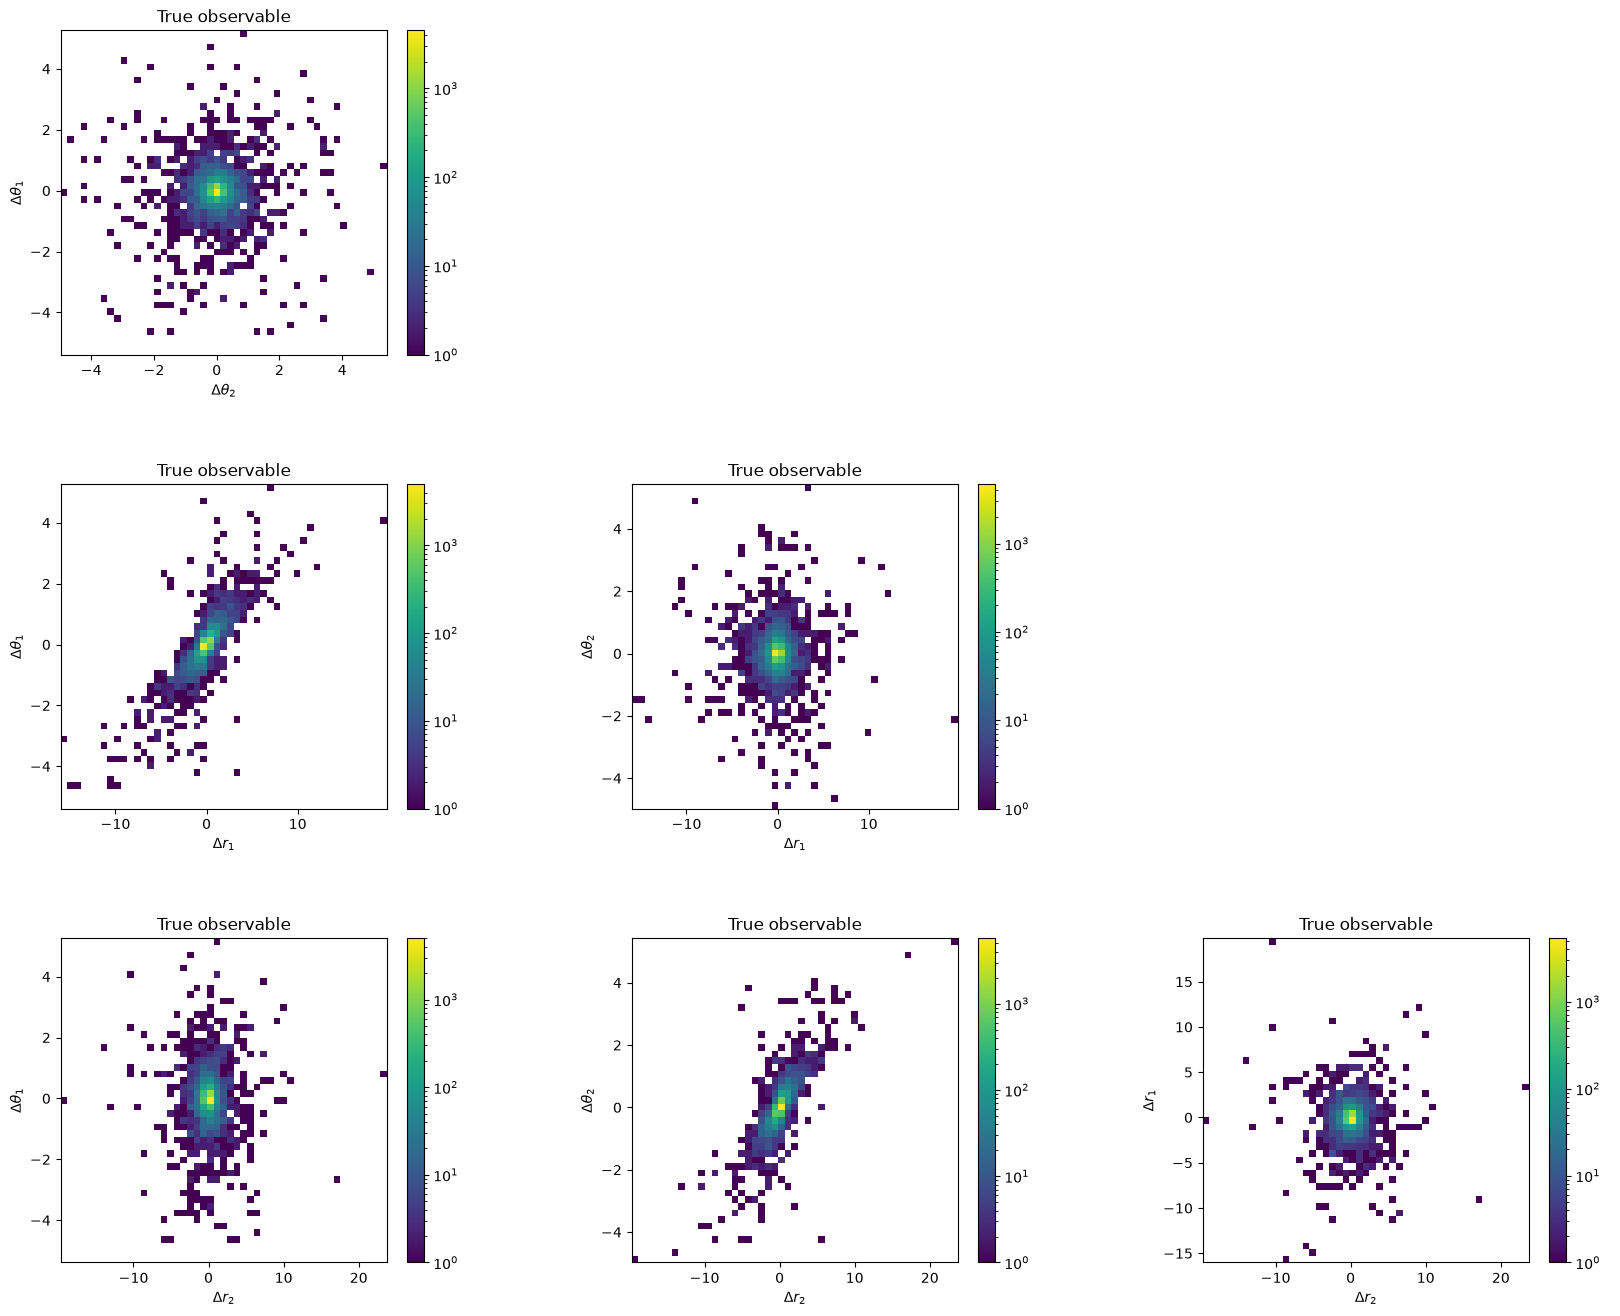

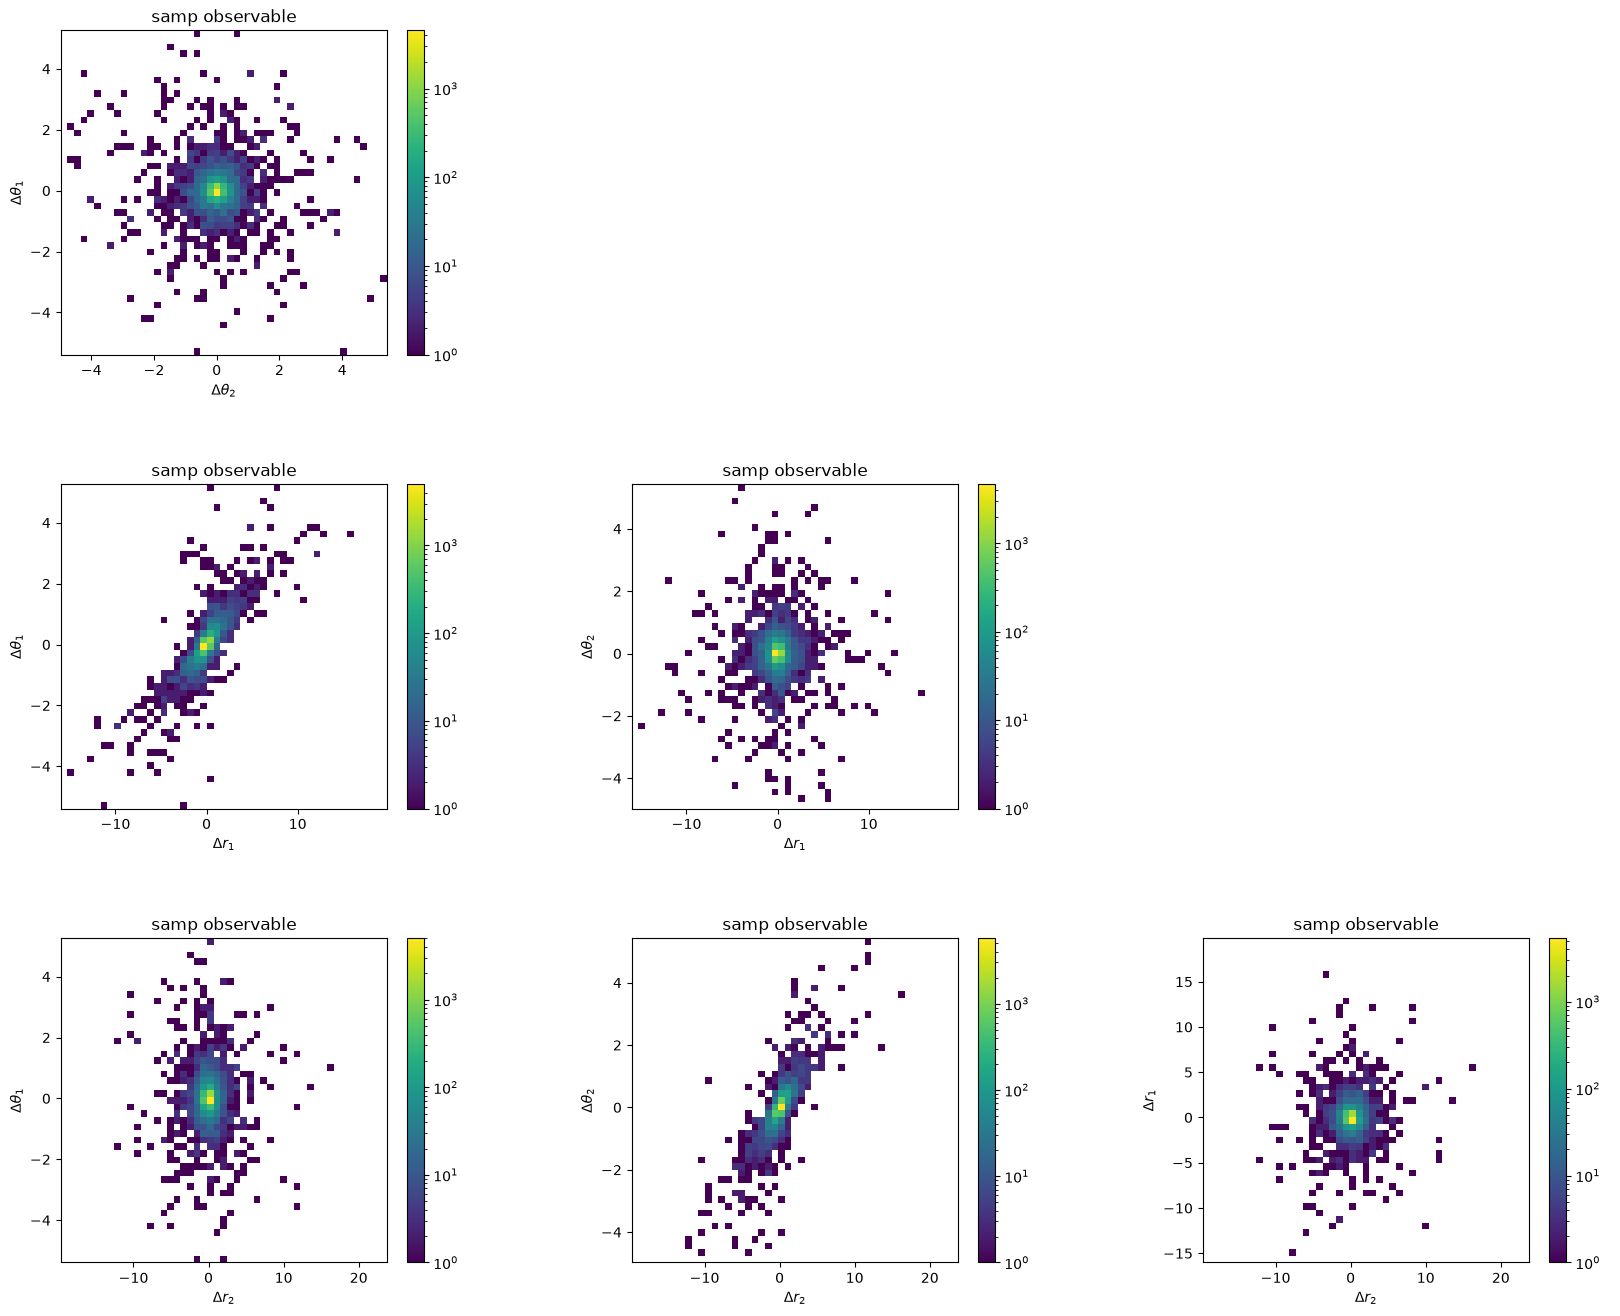

Propagating batch of 5000 for mapper update
Propagation : [====================================================================================================] 100%
Propagation done in 4152 steps, max distance 7.426
Masking 261 out of 5000 events [5.220%]
Values outside [-5,+5] : 0.675%


Log prob:   0%|          | 0/76 [00:00<?, ?it/s]

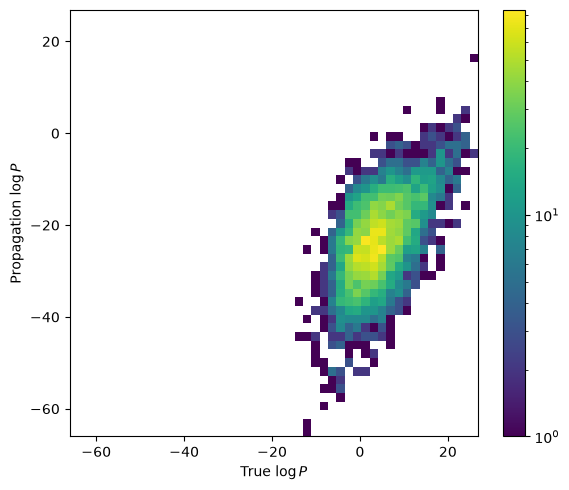

Loss =  4.46879 (sim) - -23.28008 (data) = 27.74887 (total)


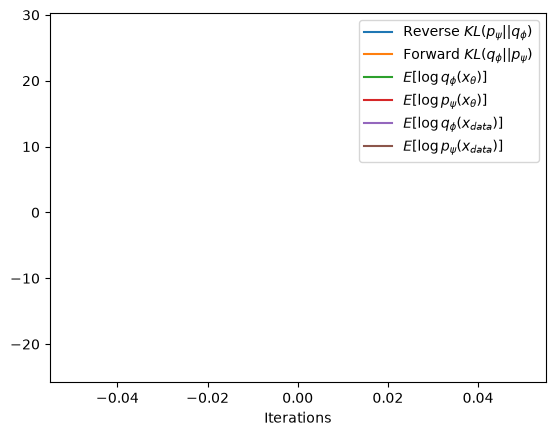

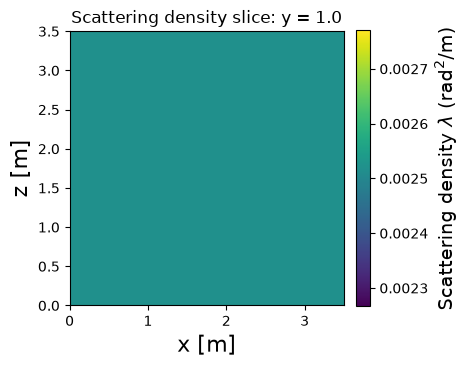

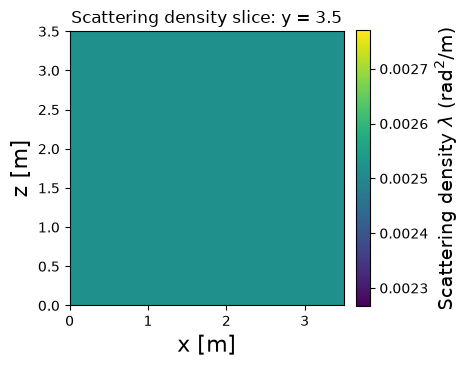

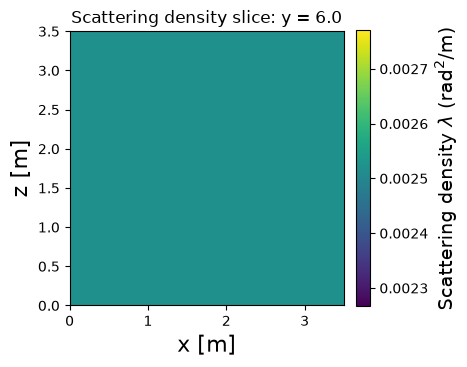

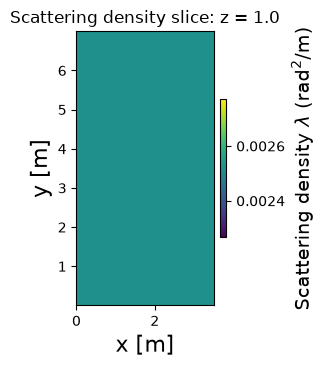

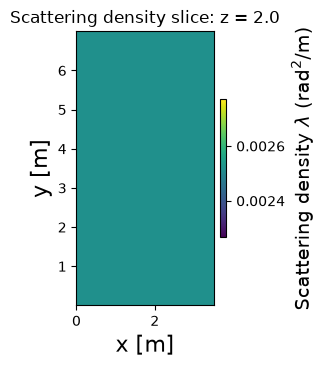

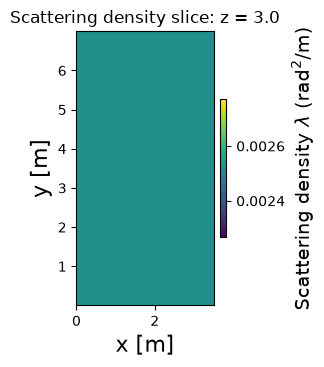

Iteration 2/1000 [ 0.20]%
Propagating simulation dataset with 100000 muons
Propagation : [====================================================================================================] 100%
Propagation done in 14000 steps, max distance 7.975
Masking 5985 out of 100000 events [5.985%]


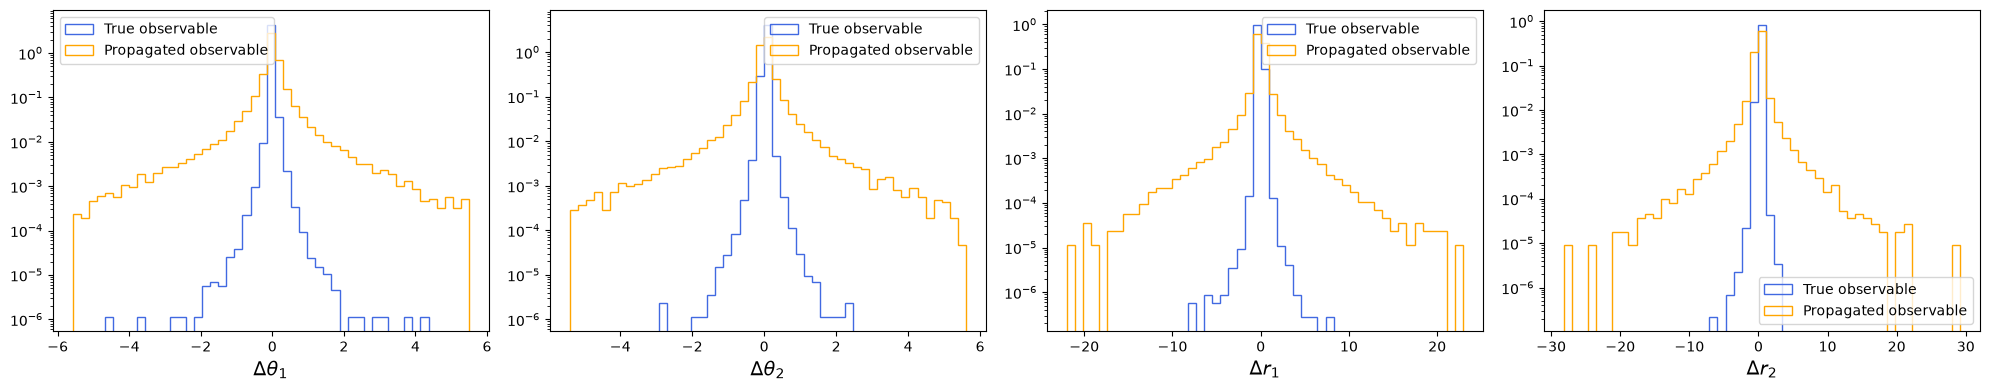

Training simulation surrogate
Epochs = 10 - LR = 1.000e-03 - batch size = 256 - Training set = 84613 [331 batches] - Validation set = 9402 [37 batches]


Training:   0%|          | 0/331 [00:00<?, ?it/s]

Validation:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch:   1/10 - Loss:   -4.454 - Val loss   -4.397


Training:   0%|          | 0/331 [00:00<?, ?it/s]

...

Epoch:   2/3 - Loss:   -4.703 - Val loss   -4.507


Training:   0%|          | 0/331 [00:00<?, ?it/s]

Validation:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch:   3/3 - Loss:   -4.703 - Val loss   -4.507


Validation:   0%|          | 0/2 [00:00<?, ?it/s]

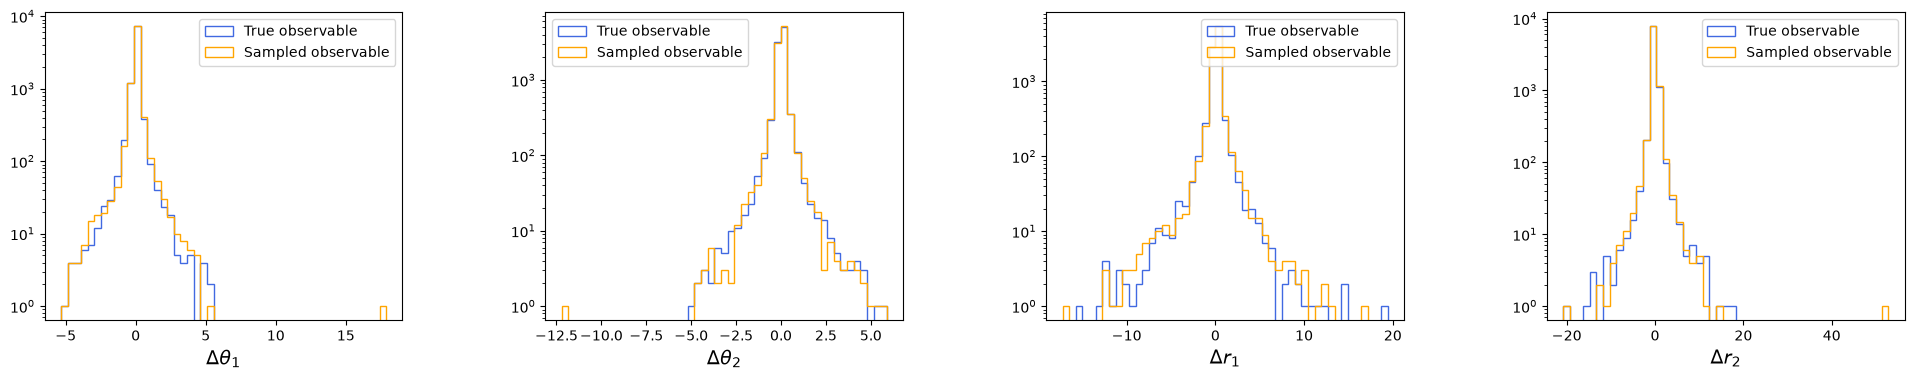

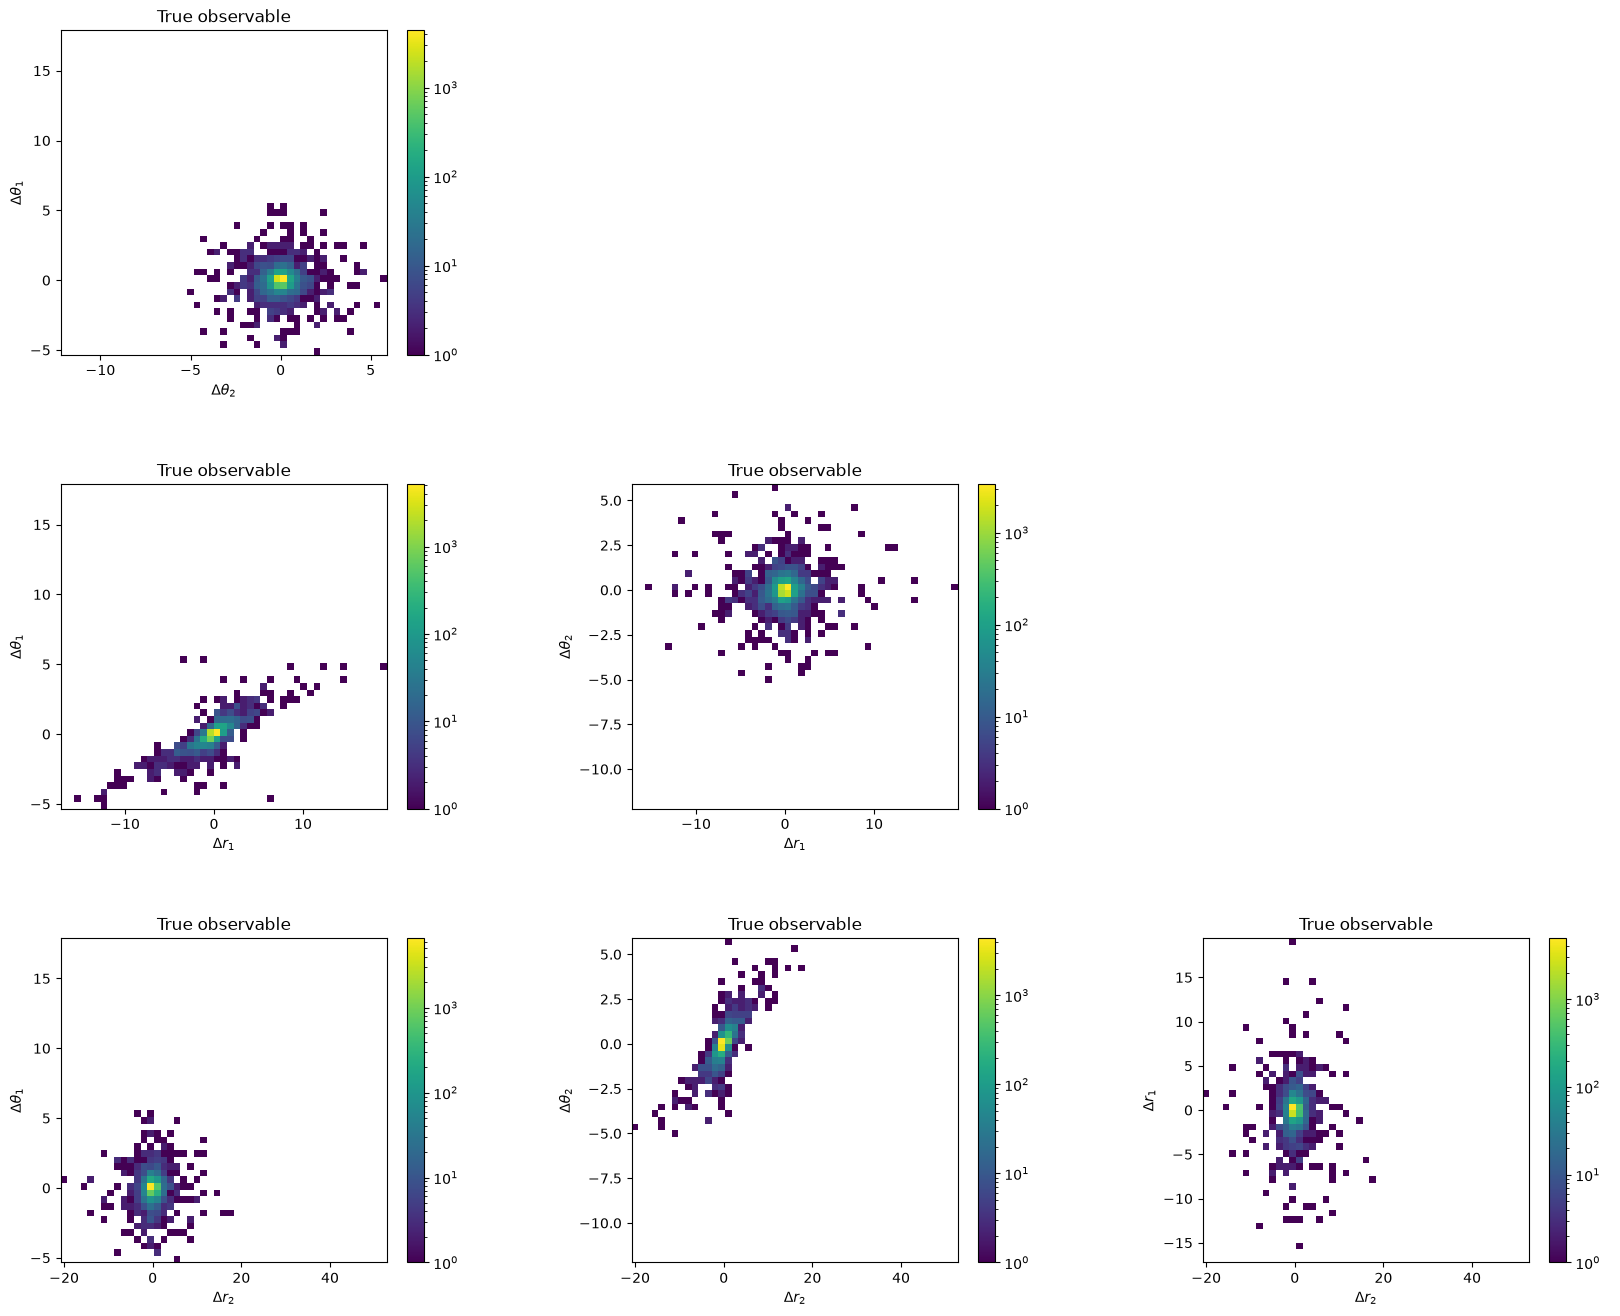

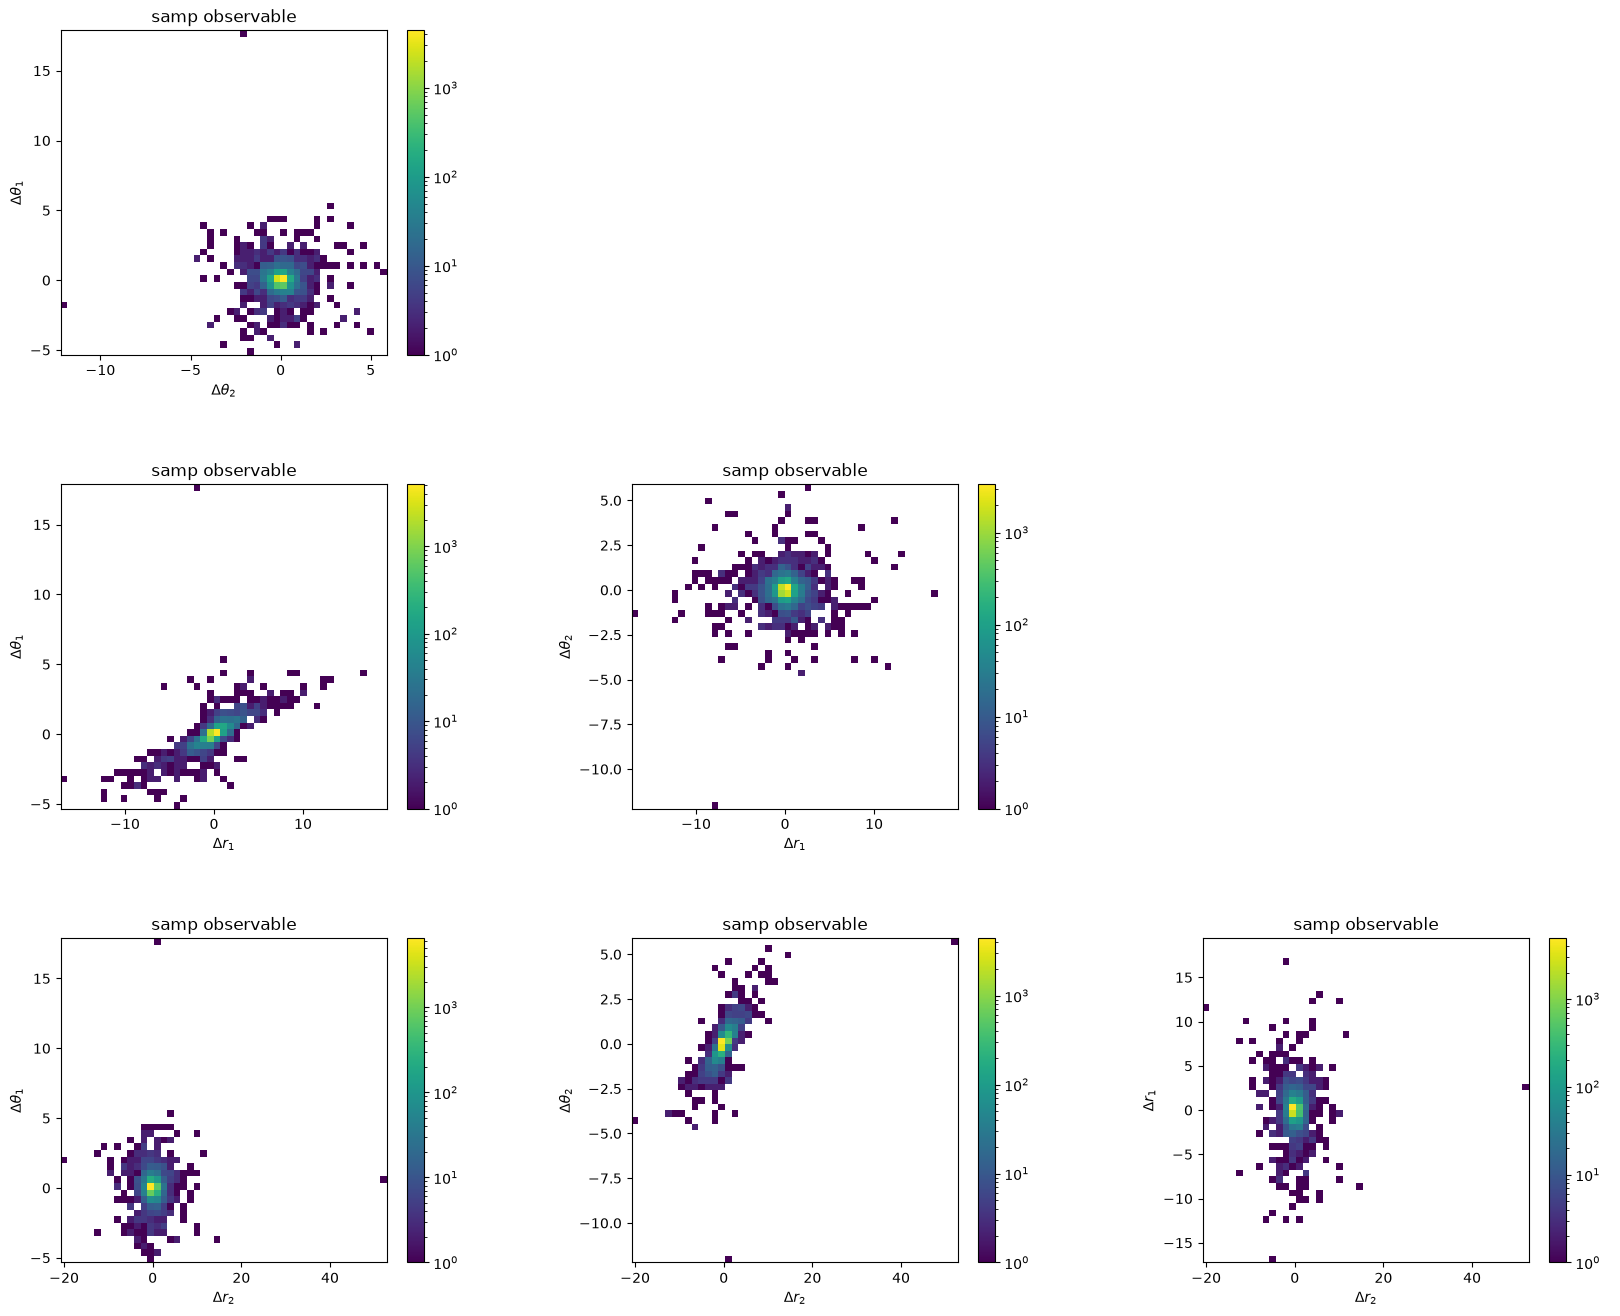

Propagating batch of 5000 for mapper update
Propagation : [====================================================================================================] 100%
Propagation done in 5814 steps, max distance 7.342
Masking 284 out of 5000 events [5.680%]
Values outside [-5,+5] : 0.848%


Log prob:   0%|          | 0/76 [00:00<?, ?it/s]

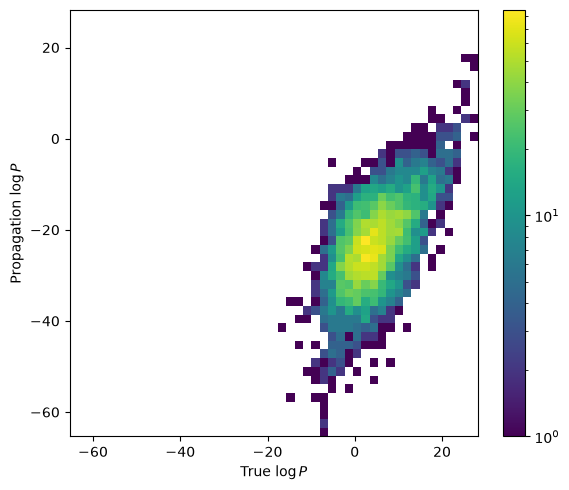

Loss =  4.65981 (sim) - -23.22761 (data) = 27.88742 (total)


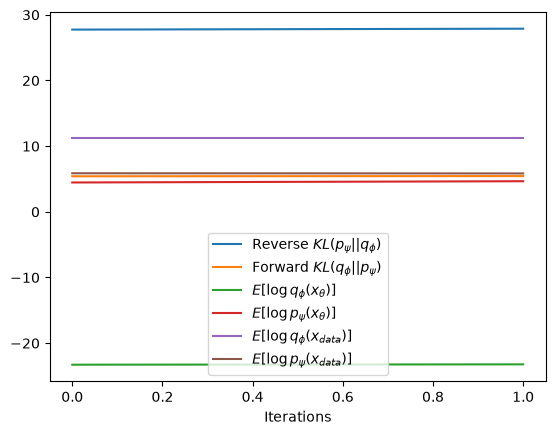

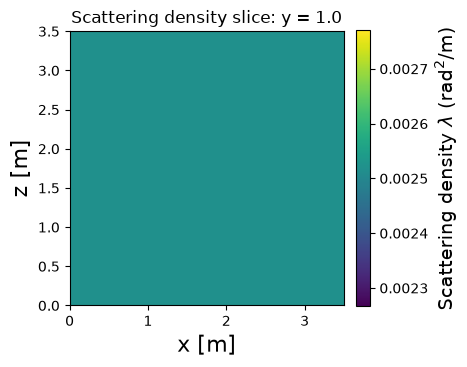

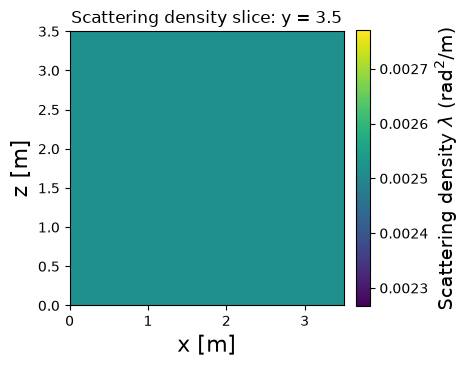

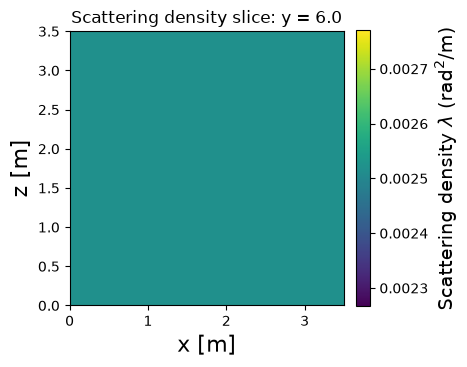

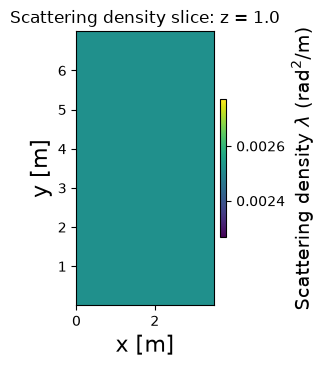

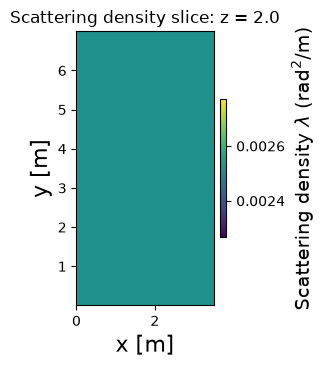

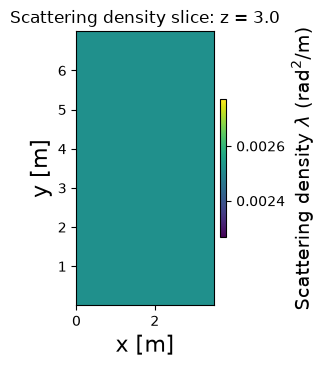

Iteration 3/1000 [ 0.30]%
Propagating simulation dataset with 100000 muons
Propagation : [====================================================================================================] 100%
Propagation done in 12145 steps, max distance 8.030
Masking 5852 out of 100000 events [5.852%]


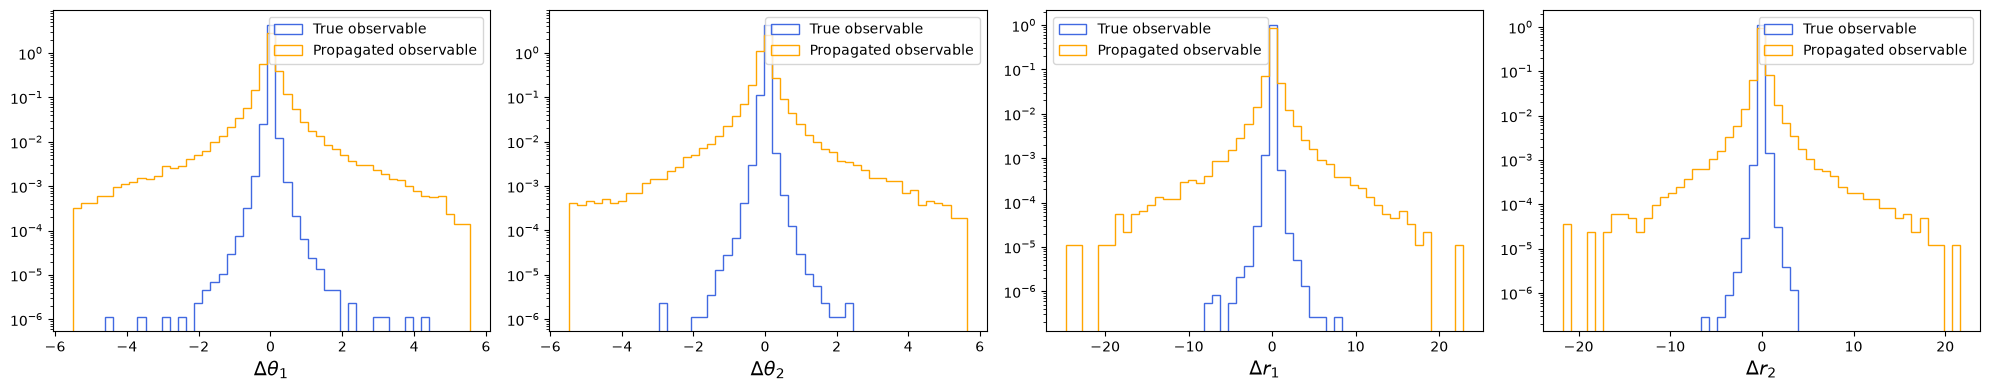

Training simulation surrogate
Epochs = 10 - LR = 1.000e-03 - batch size = 256 - Training set = 84733 [331 batches] - Validation set = 9415 [37 batches]


Training:   0%|          | 0/331 [00:00<?, ?it/s]

Validation:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch:   1/10 - Loss:   -4.506 - Val loss   -4.525


Training:   0%|          | 0/331 [00:00<?, ?it/s]

...

Epoch:   2/3 - Loss:   -4.768 - Val loss   -4.649


Training:   0%|          | 0/331 [00:00<?, ?it/s]

Validation:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch:   3/3 - Loss:   -4.768 - Val loss   -4.649


Validation:   0%|          | 0/2 [00:00<?, ?it/s]

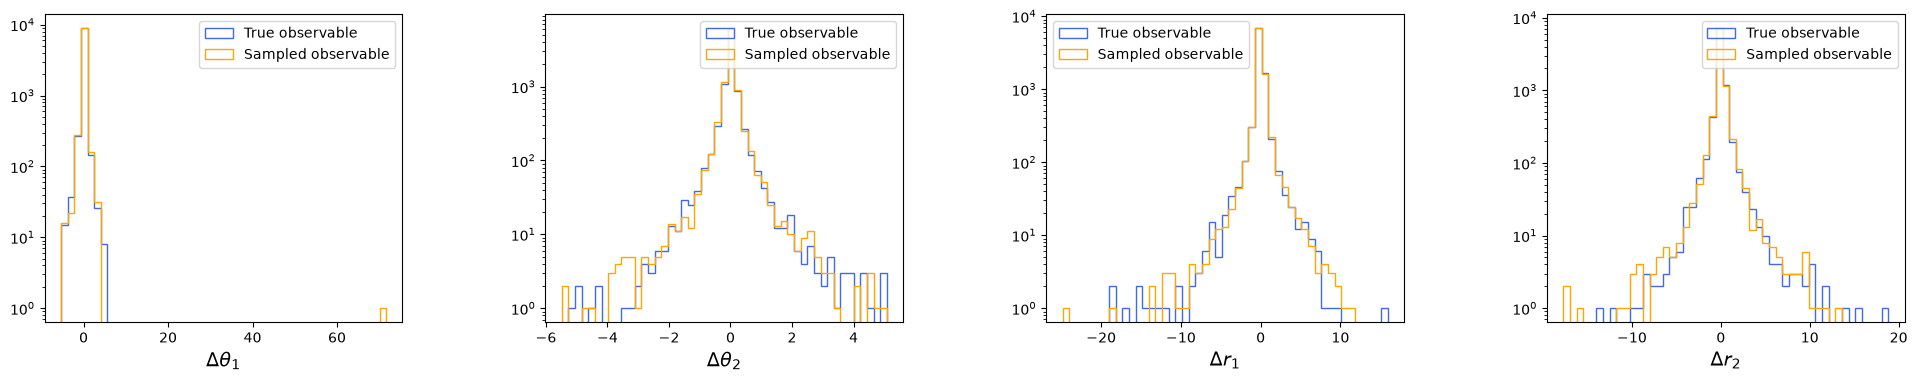

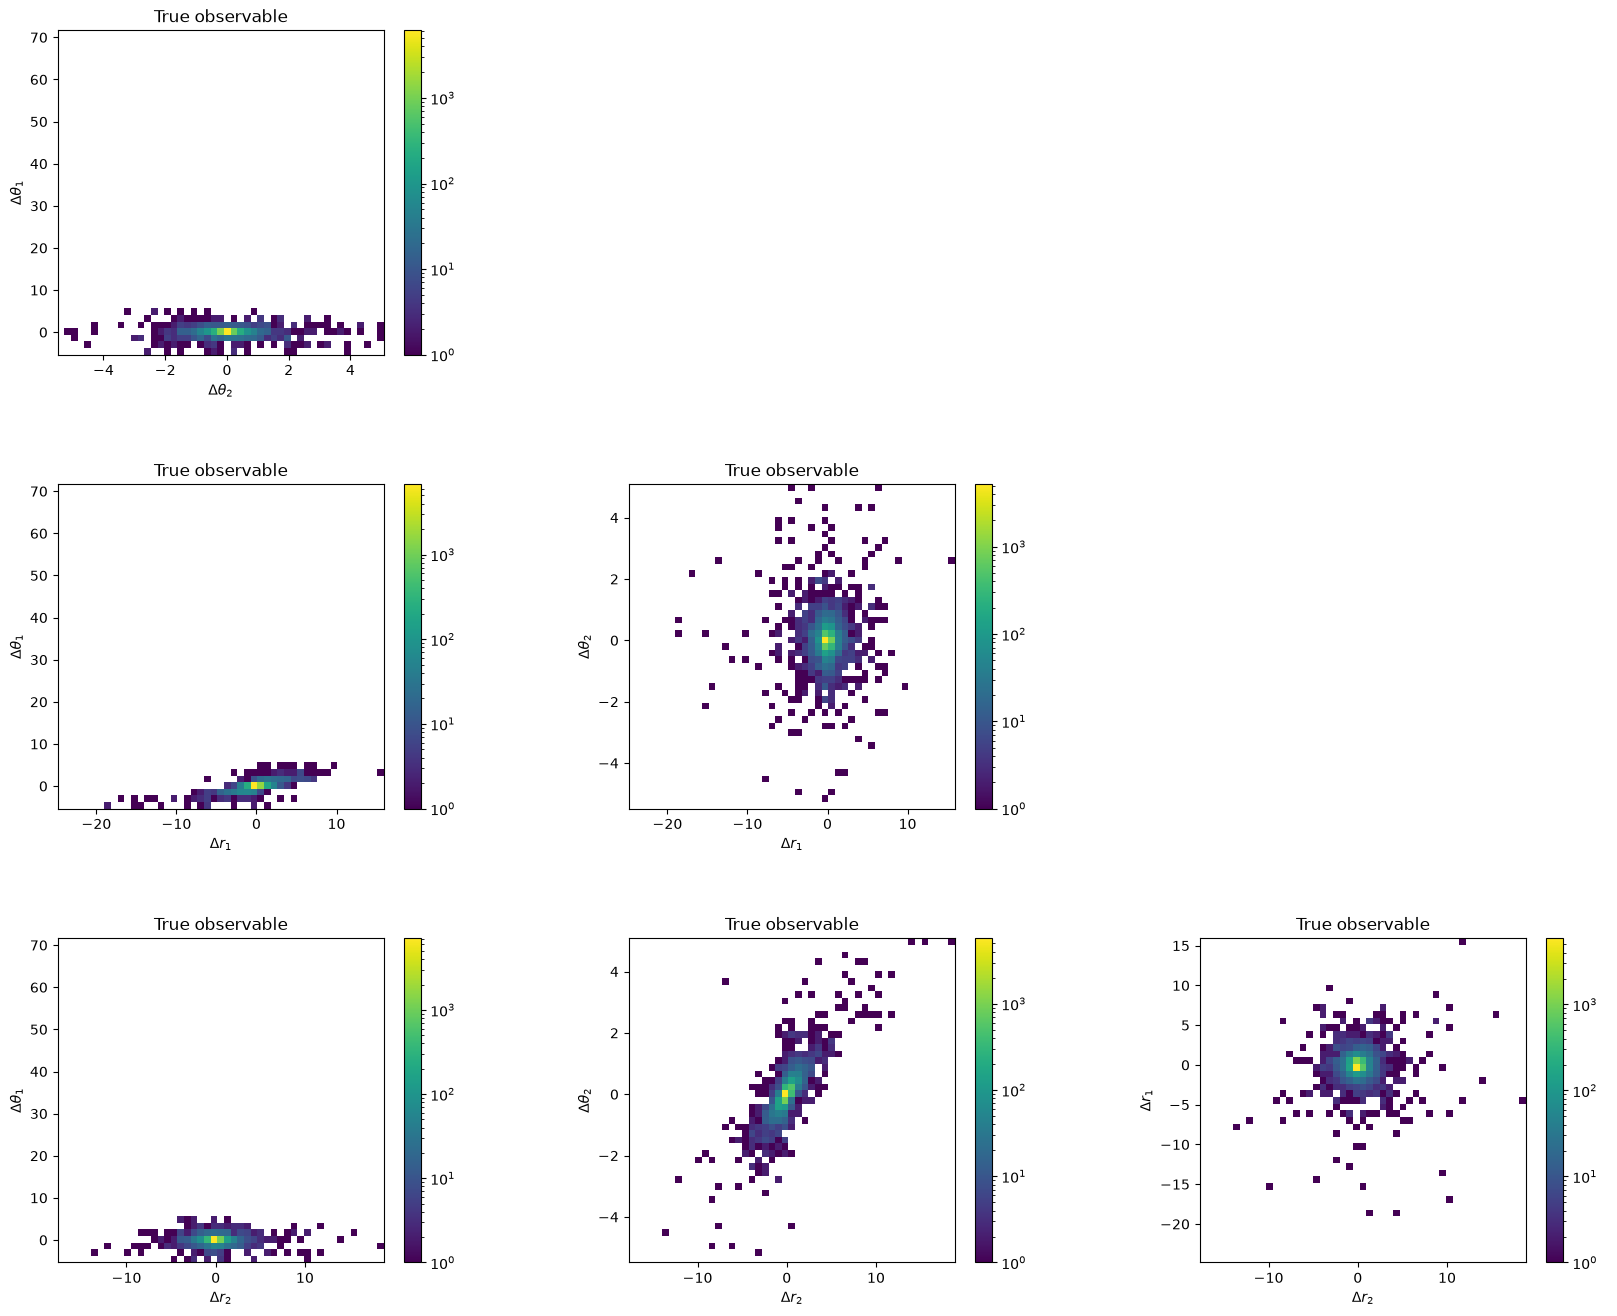

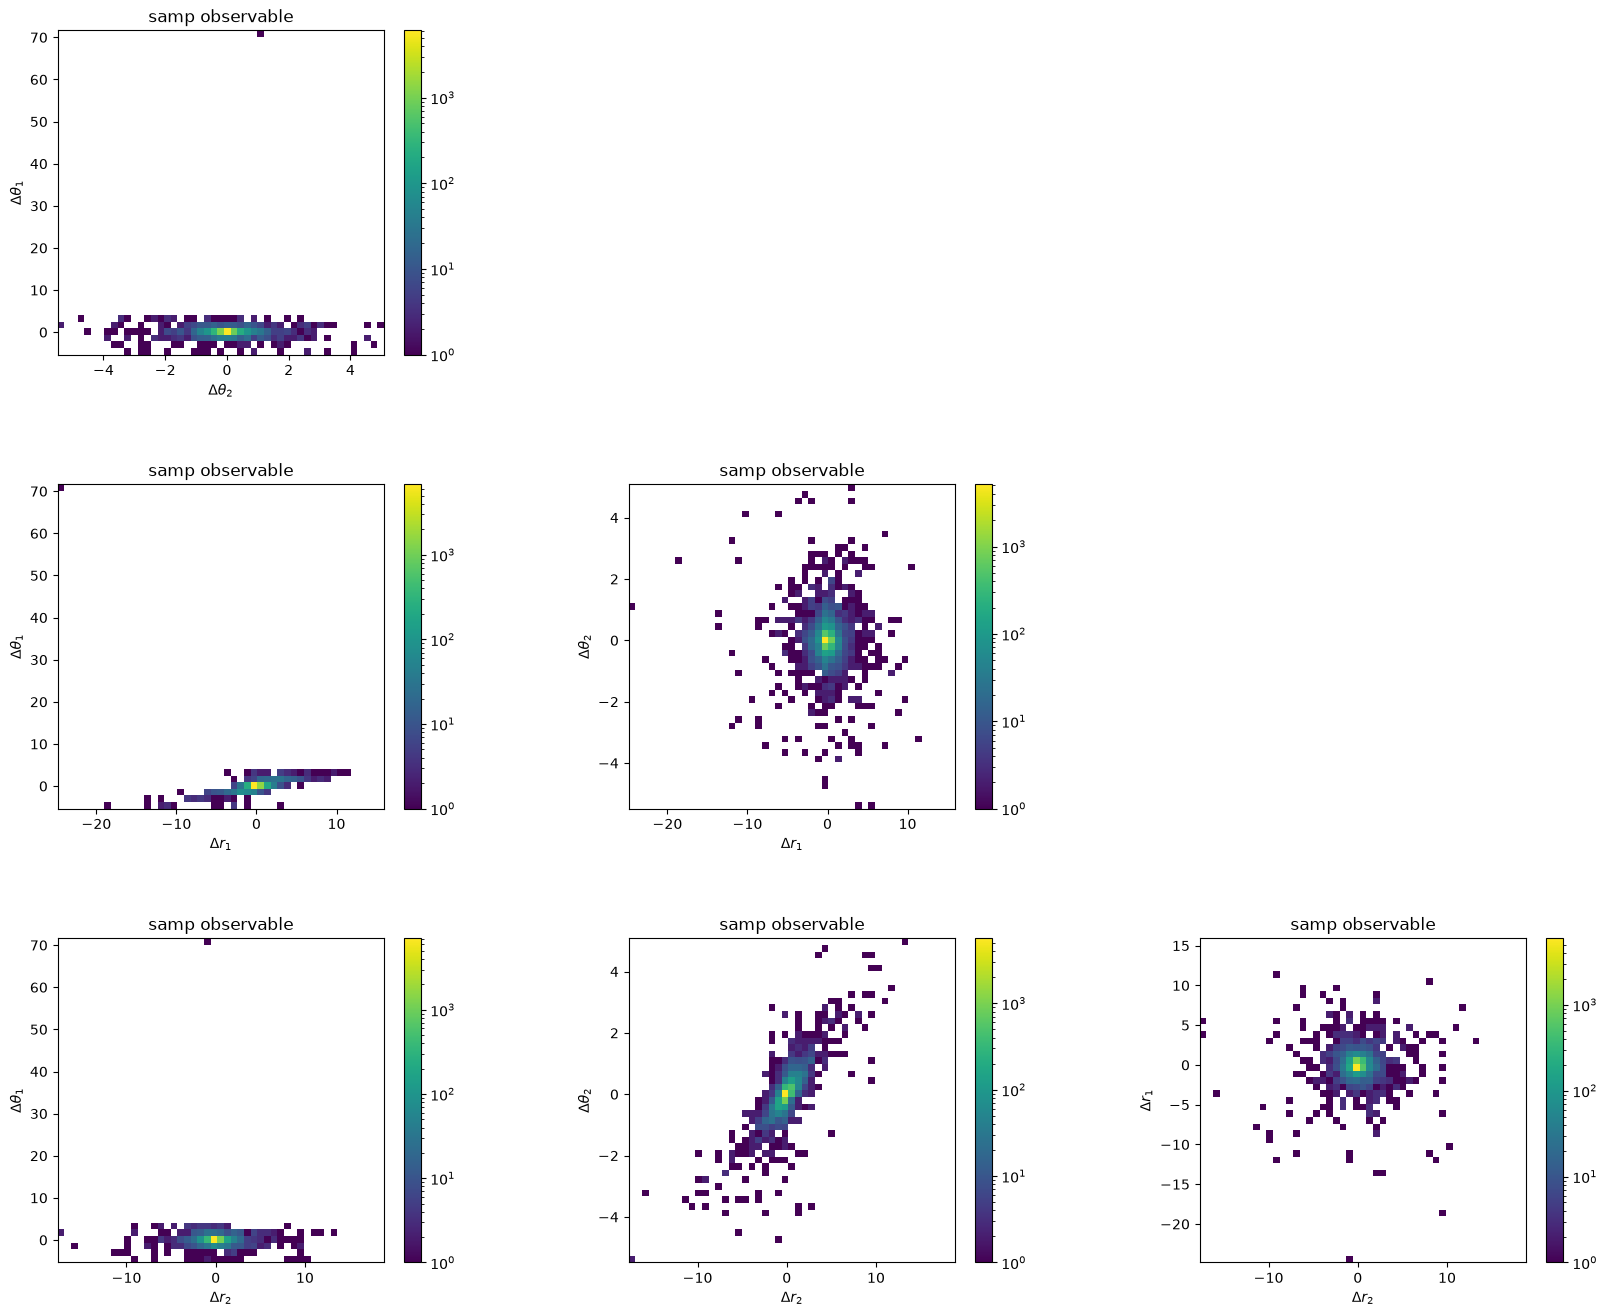

Propagating batch of 5000 for mapper update
Propagation : [====================================================================================================] 100%
Propagation done in 3875 steps, max distance 7.921
Masking 287 out of 5000 events [5.740%]
Values outside [-5,+5] : 0.700%


Log prob:   0%|          | 0/76 [00:00<?, ?it/s]

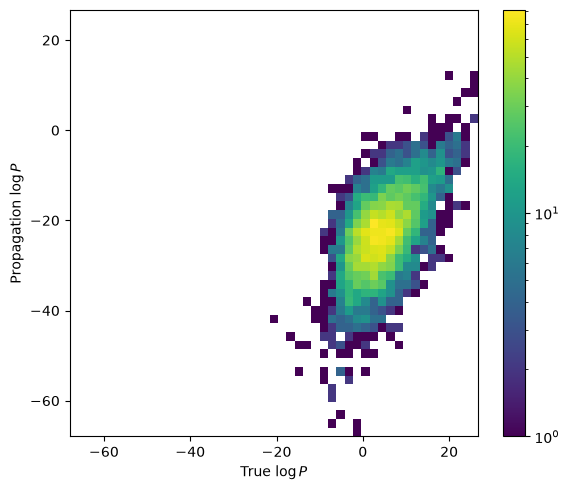

Loss =  4.71299 (sim) - -23.03488 (data) = 27.74787 (total)


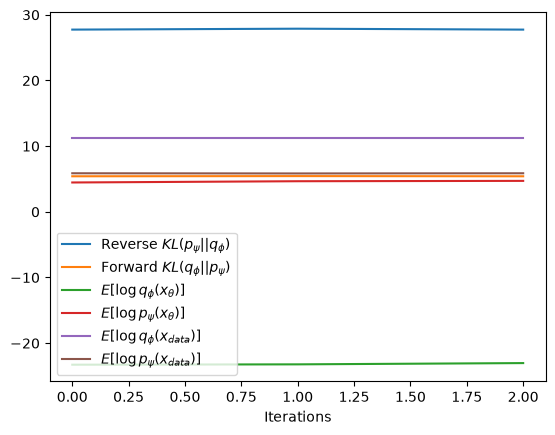

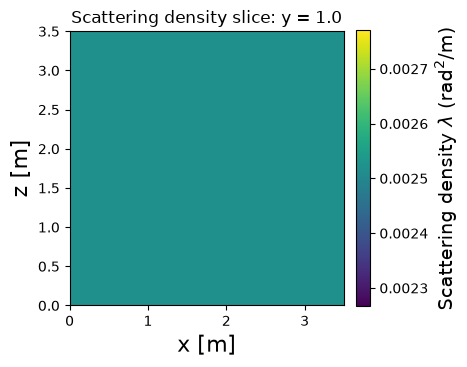

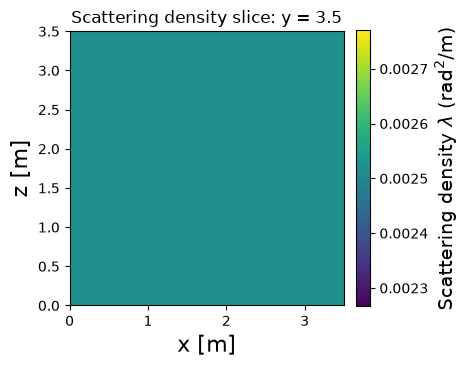

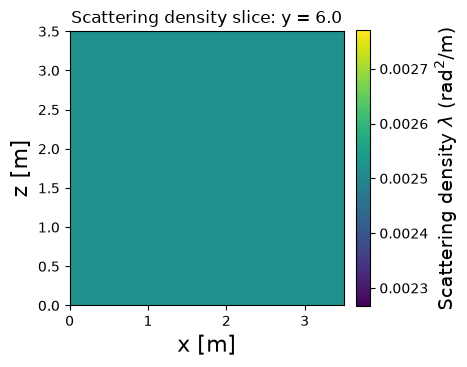

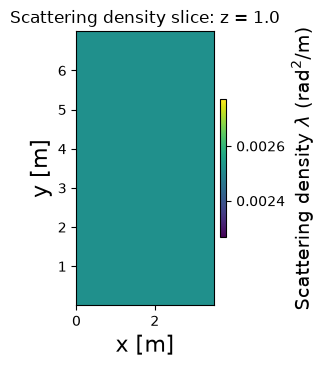

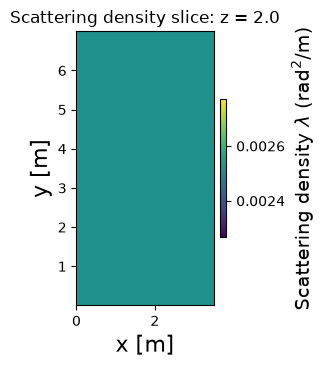

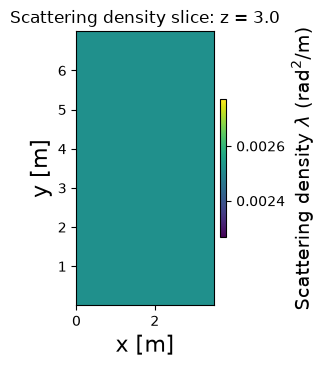

Iteration 4/1000 [ 0.40]%
Propagating simulation dataset with 100000 muons
Propagation : [====================================================================================================] 100%
Propagation done in 9049 steps, max distance 8.125
Masking 5852 out of 100000 events [5.852%]


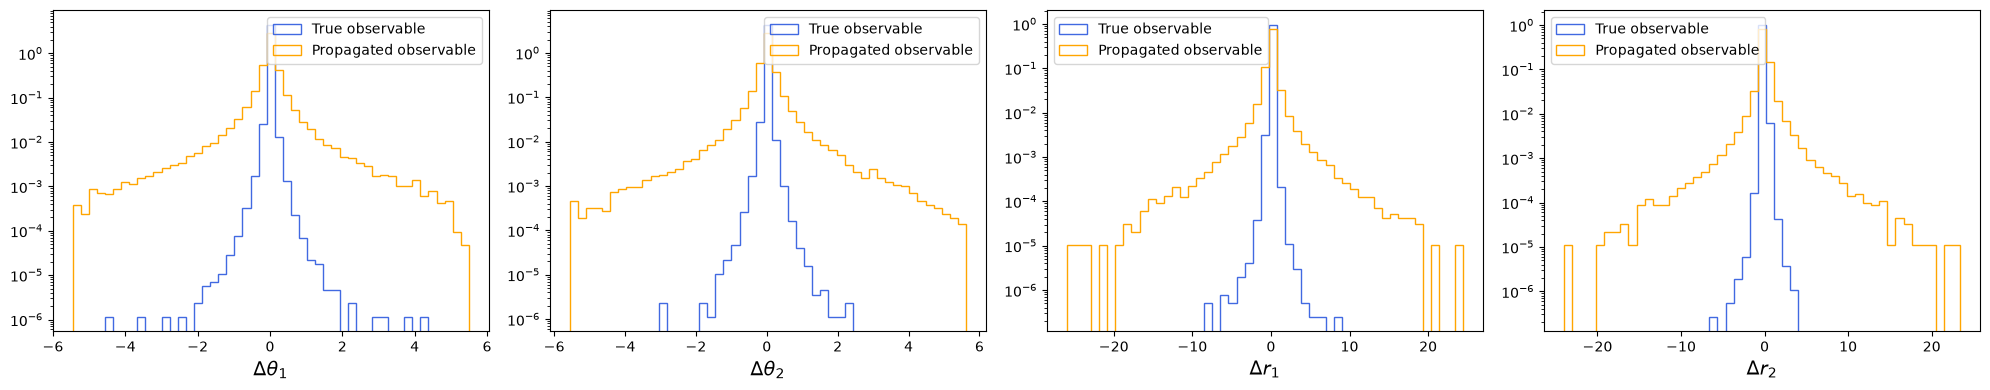

Training simulation surrogate
Epochs = 10 - LR = 1.000e-03 - batch size = 256 - Training set = 84733 [331 batches] - Validation set = 9415 [37 batches]


Training:   0%|          | 0/331 [00:00<?, ?it/s]

Validation:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch:   1/10 - Loss:   -4.512 - Val loss   -4.608


Training:   0%|          | 0/331 [00:00<?, ?it/s]

...

Epoch:   2/3 - Loss:   -4.786 - Val loss   -4.672


Training:   0%|          | 0/331 [00:00<?, ?it/s]

Validation:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch:   3/3 - Loss:   -4.787 - Val loss   -4.671


Validation:   0%|          | 0/2 [00:00<?, ?it/s]

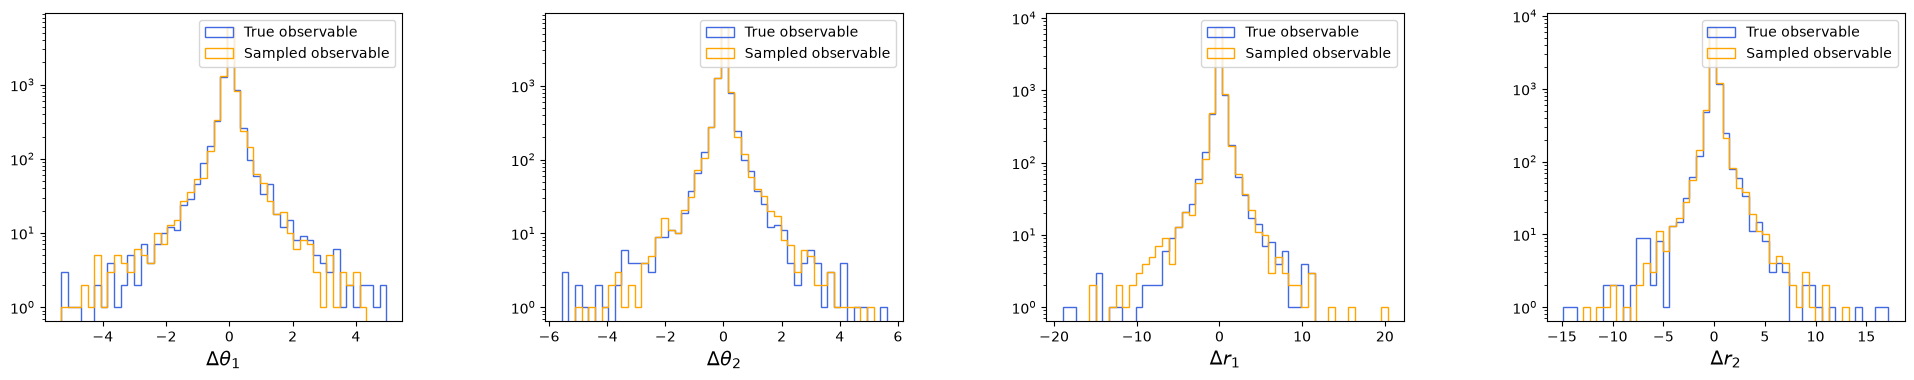

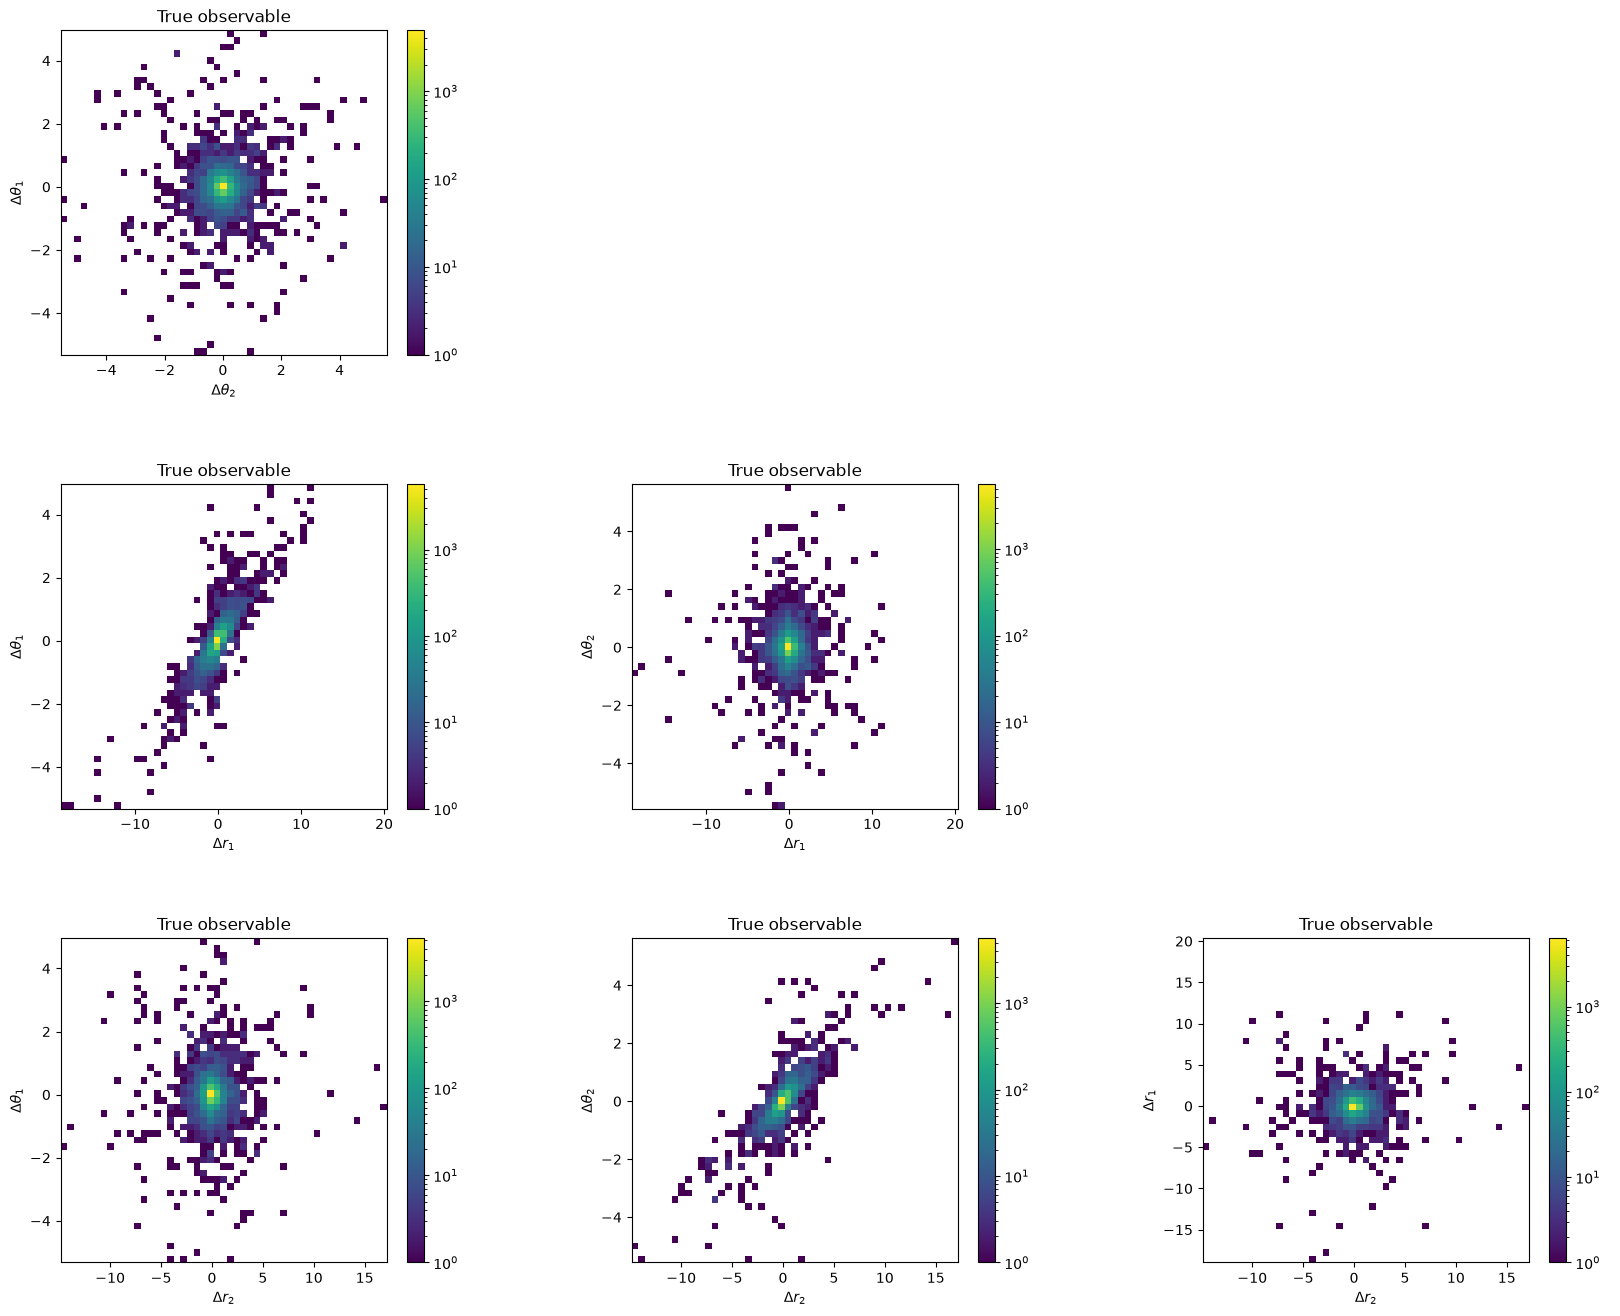

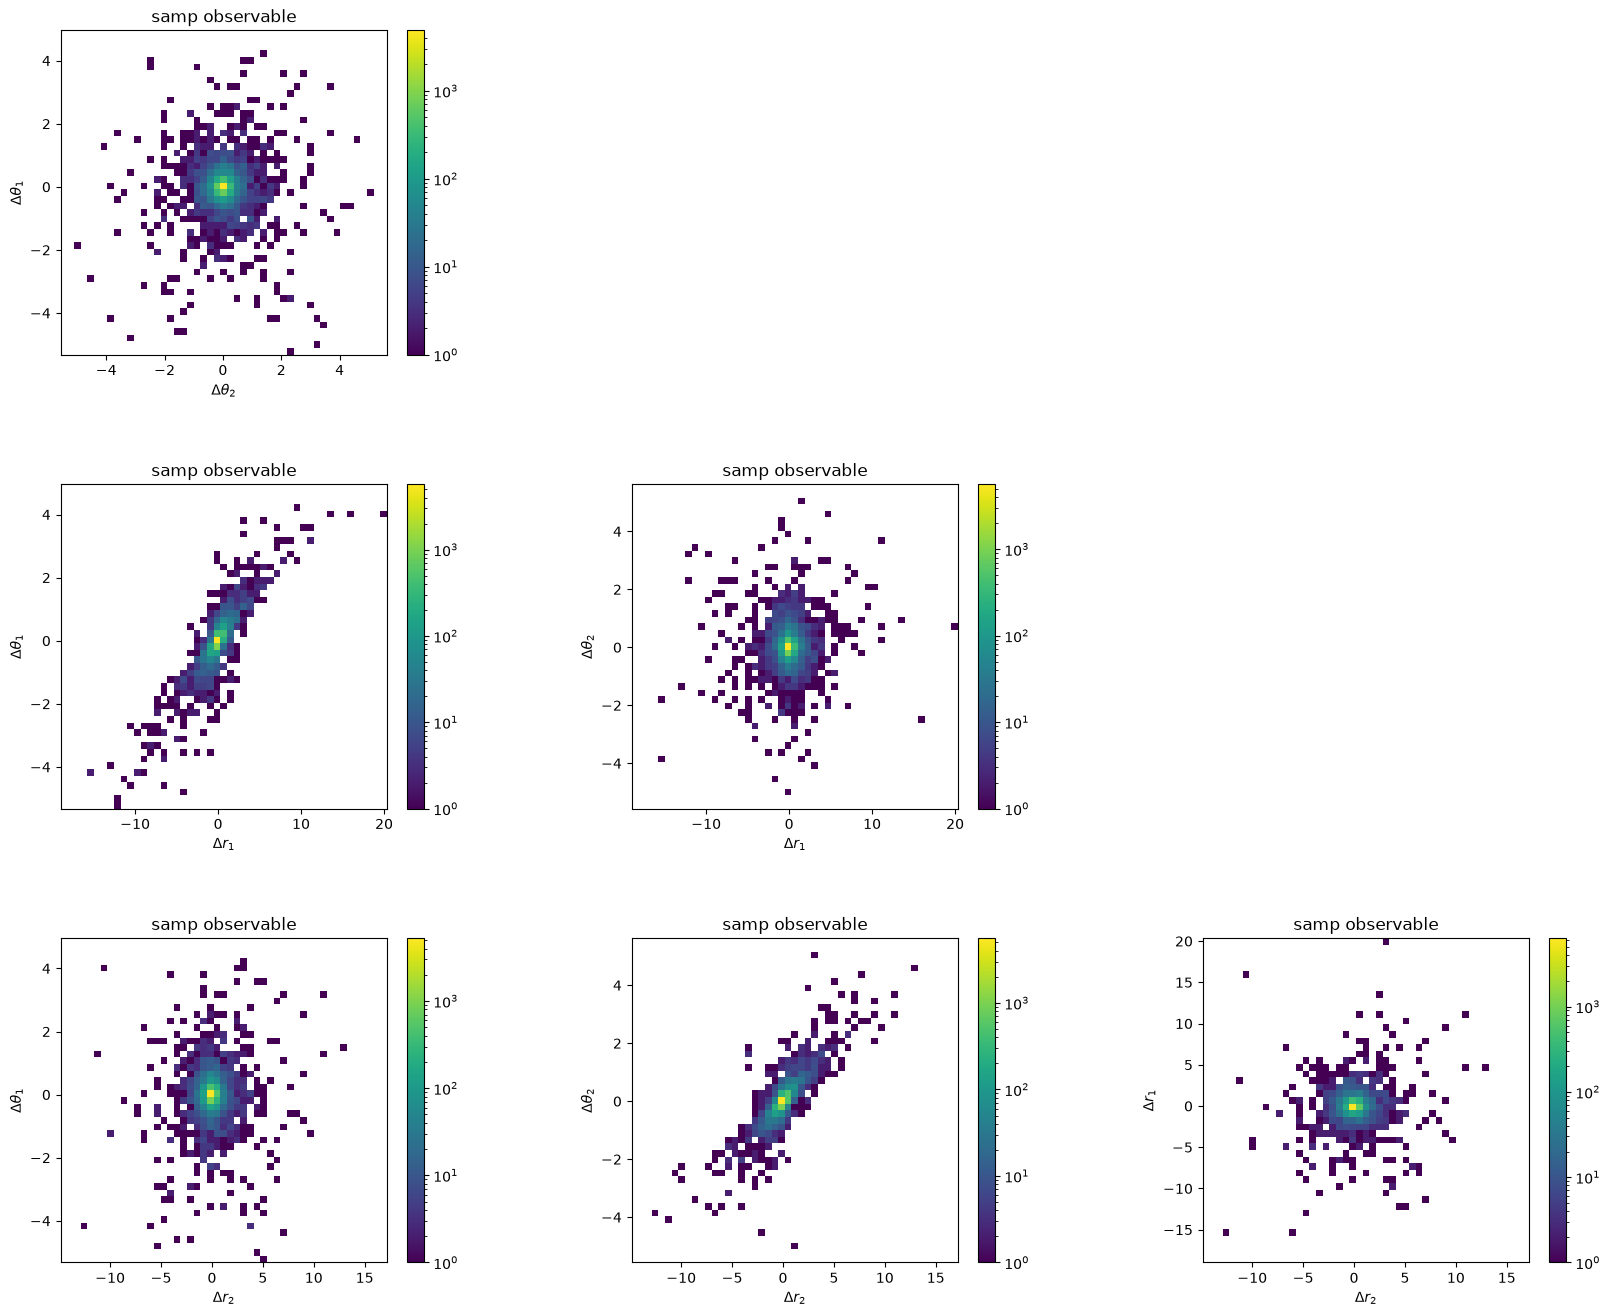

Propagating batch of 5000 for mapper update
Propagation : [====================================================================================================] 100%
Propagation done in 2236 steps, max distance 7.529
Masking 296 out of 5000 events [5.920%]
Values outside [-5,+5] : 0.404%


Log prob:   0%|          | 0/76 [00:00<?, ?it/s]

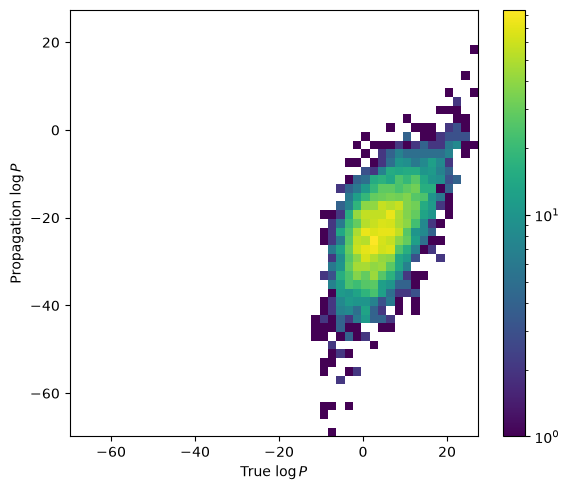

Loss =  4.61906 (sim) - -23.11263 (data) = 27.73169 (total)


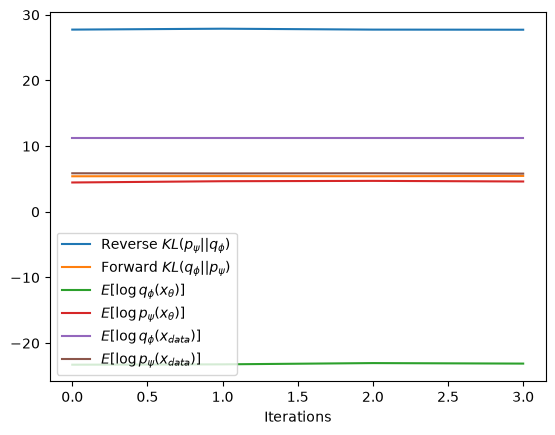

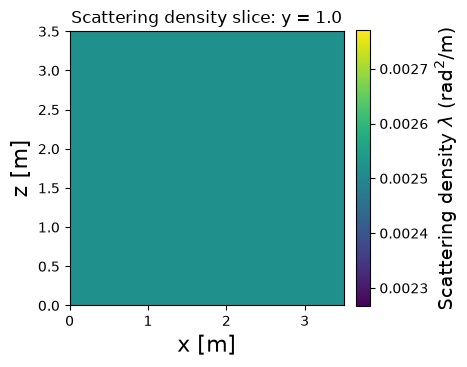

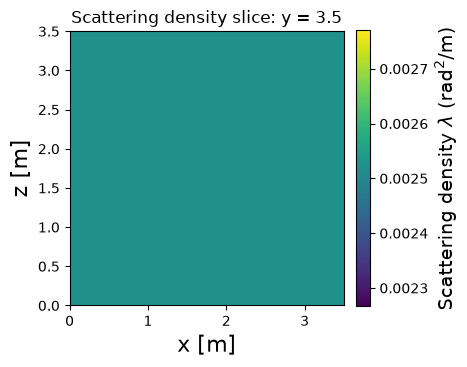

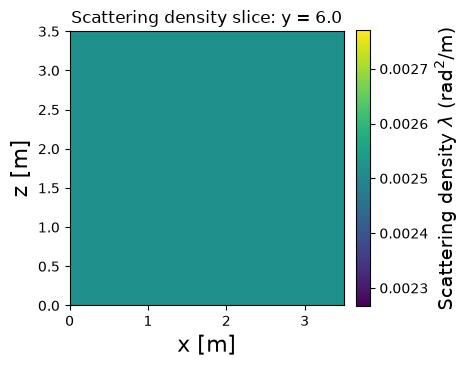

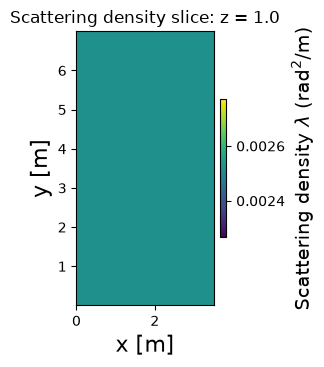

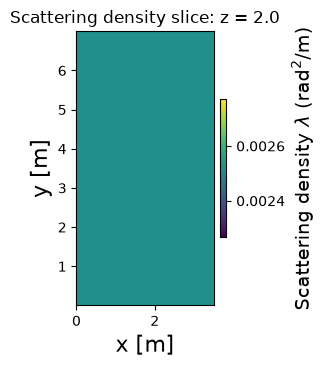

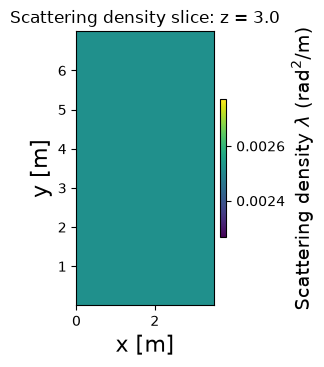

Iteration 5/1000 [ 0.50]%
Propagating simulation dataset with 100000 muons
Propagation : [====================================================================================================] 100%
Propagation done in 10131 steps, max distance 7.898
Masking 5805 out of 100000 events [5.805%]


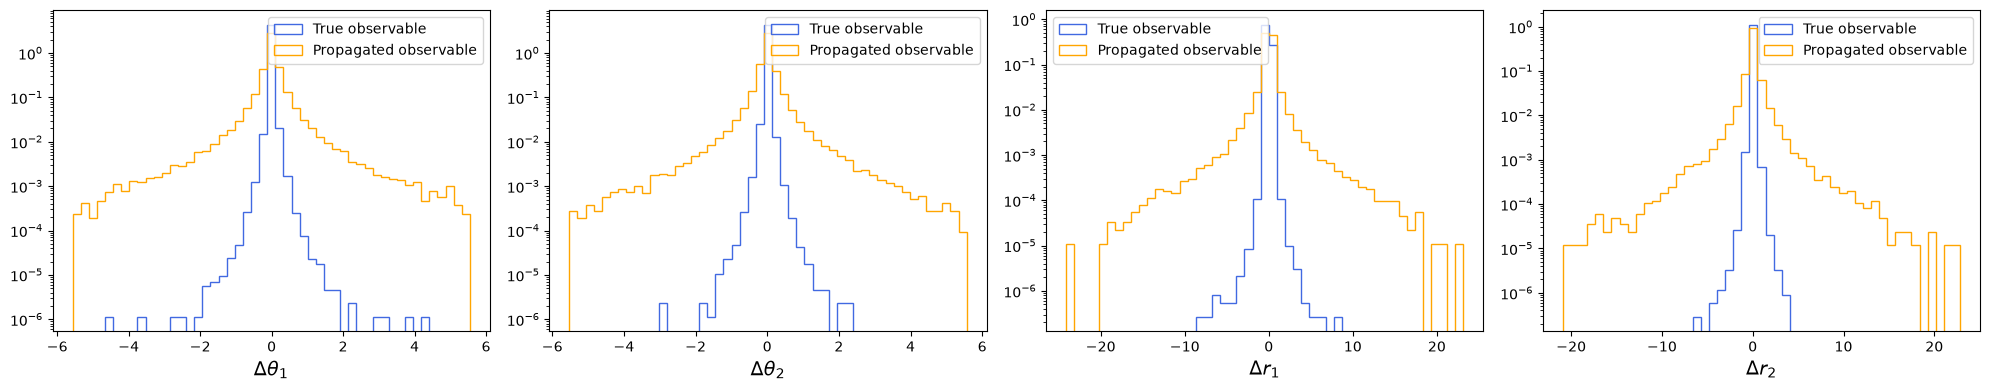

Training simulation surrogate
Epochs = 10 - LR = 1.000e-03 - batch size = 256 - Training set = 84775 [332 batches] - Validation set = 9420 [37 batches]


Training:   0%|          | 0/332 [00:00<?, ?it/s]

Validation:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch:   1/10 - Loss:   -4.469 - Val loss   -4.571


Training:   0%|          | 0/332 [00:00<?, ?it/s]

...

Epoch:   2/3 - Loss:   -4.731 - Val loss   -4.642


Training:   0%|          | 0/332 [00:00<?, ?it/s]

Validation:   0%|          | 0/37 [00:00<?, ?it/s]

Epoch:   3/3 - Loss:   -4.733 - Val loss   -4.644


Validation:   0%|          | 0/2 [00:00<?, ?it/s]

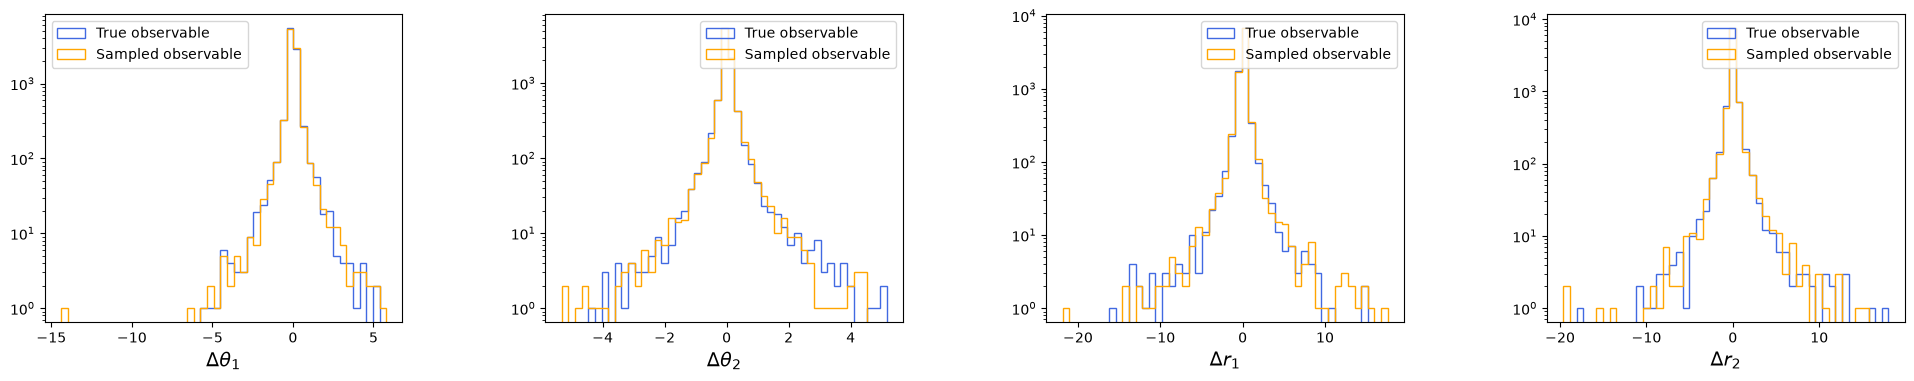

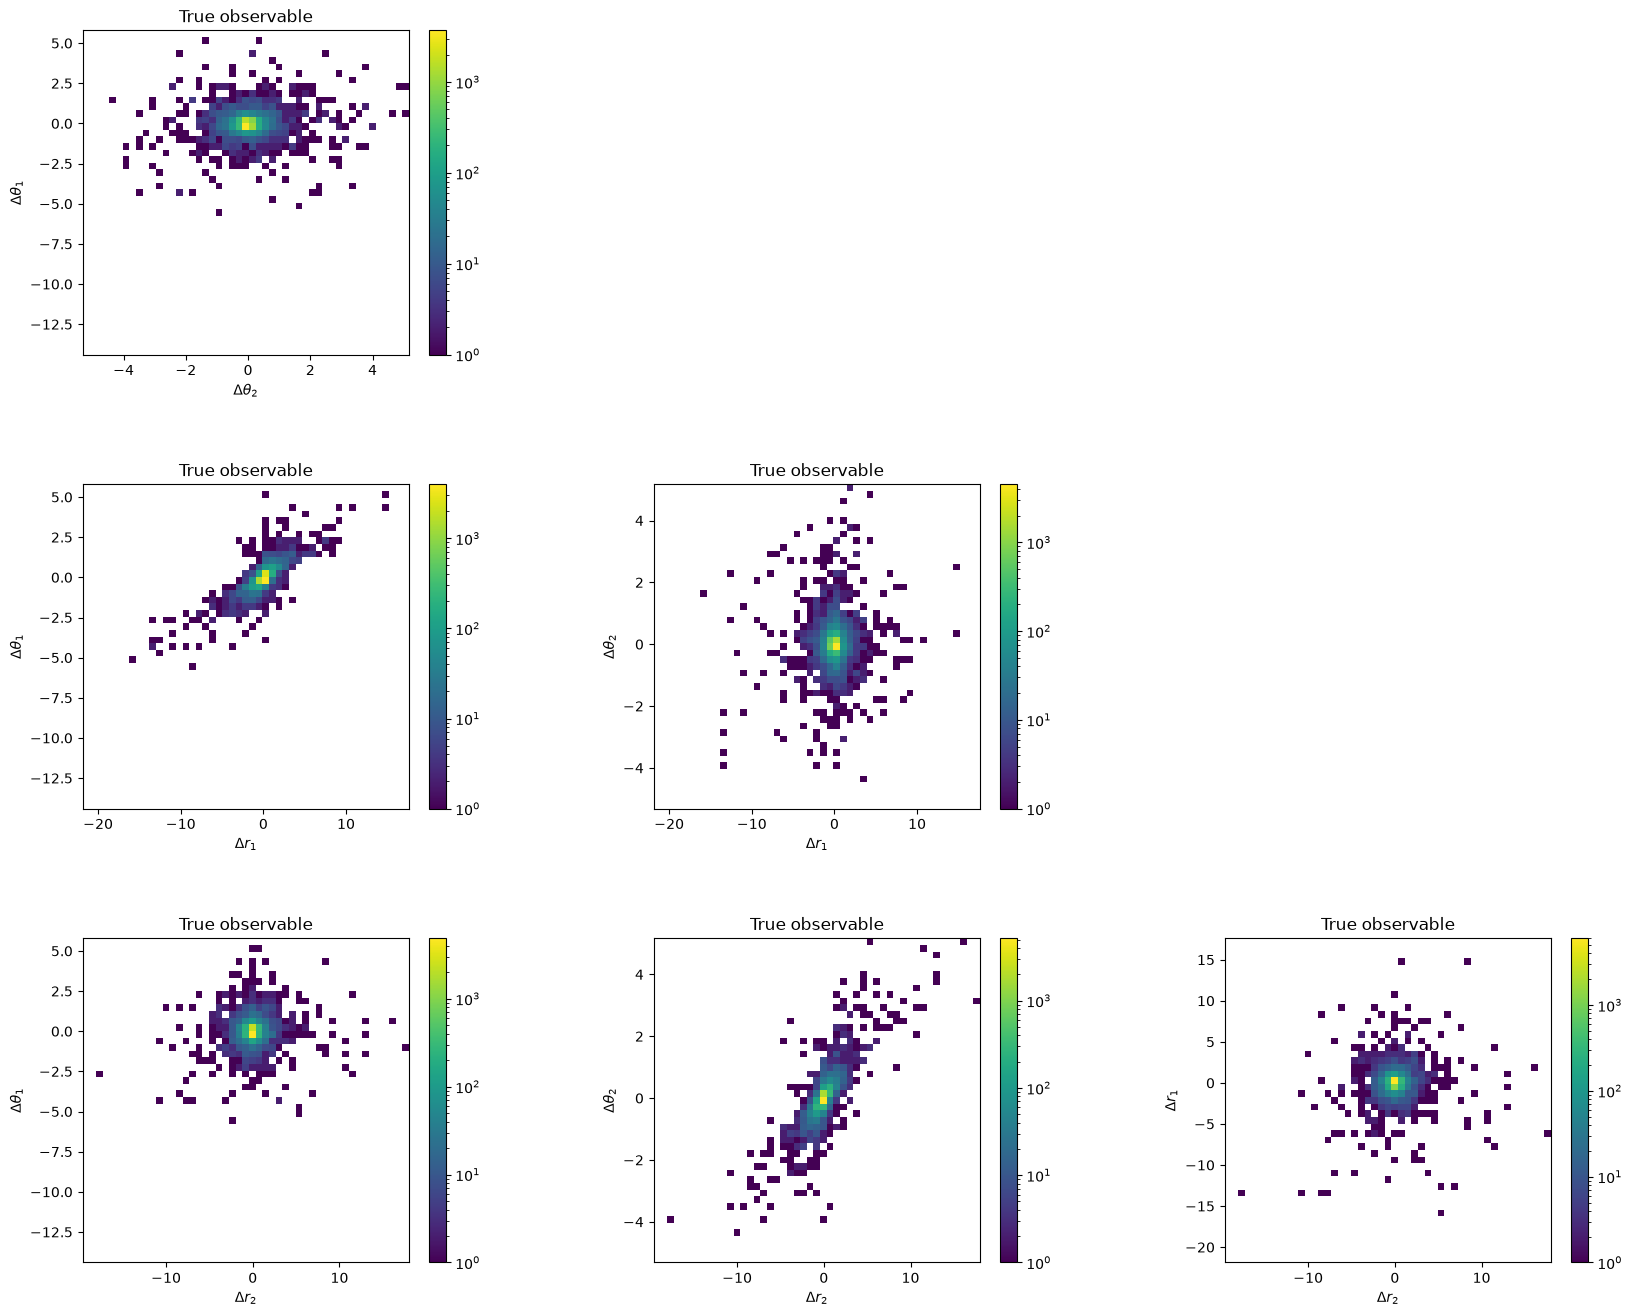

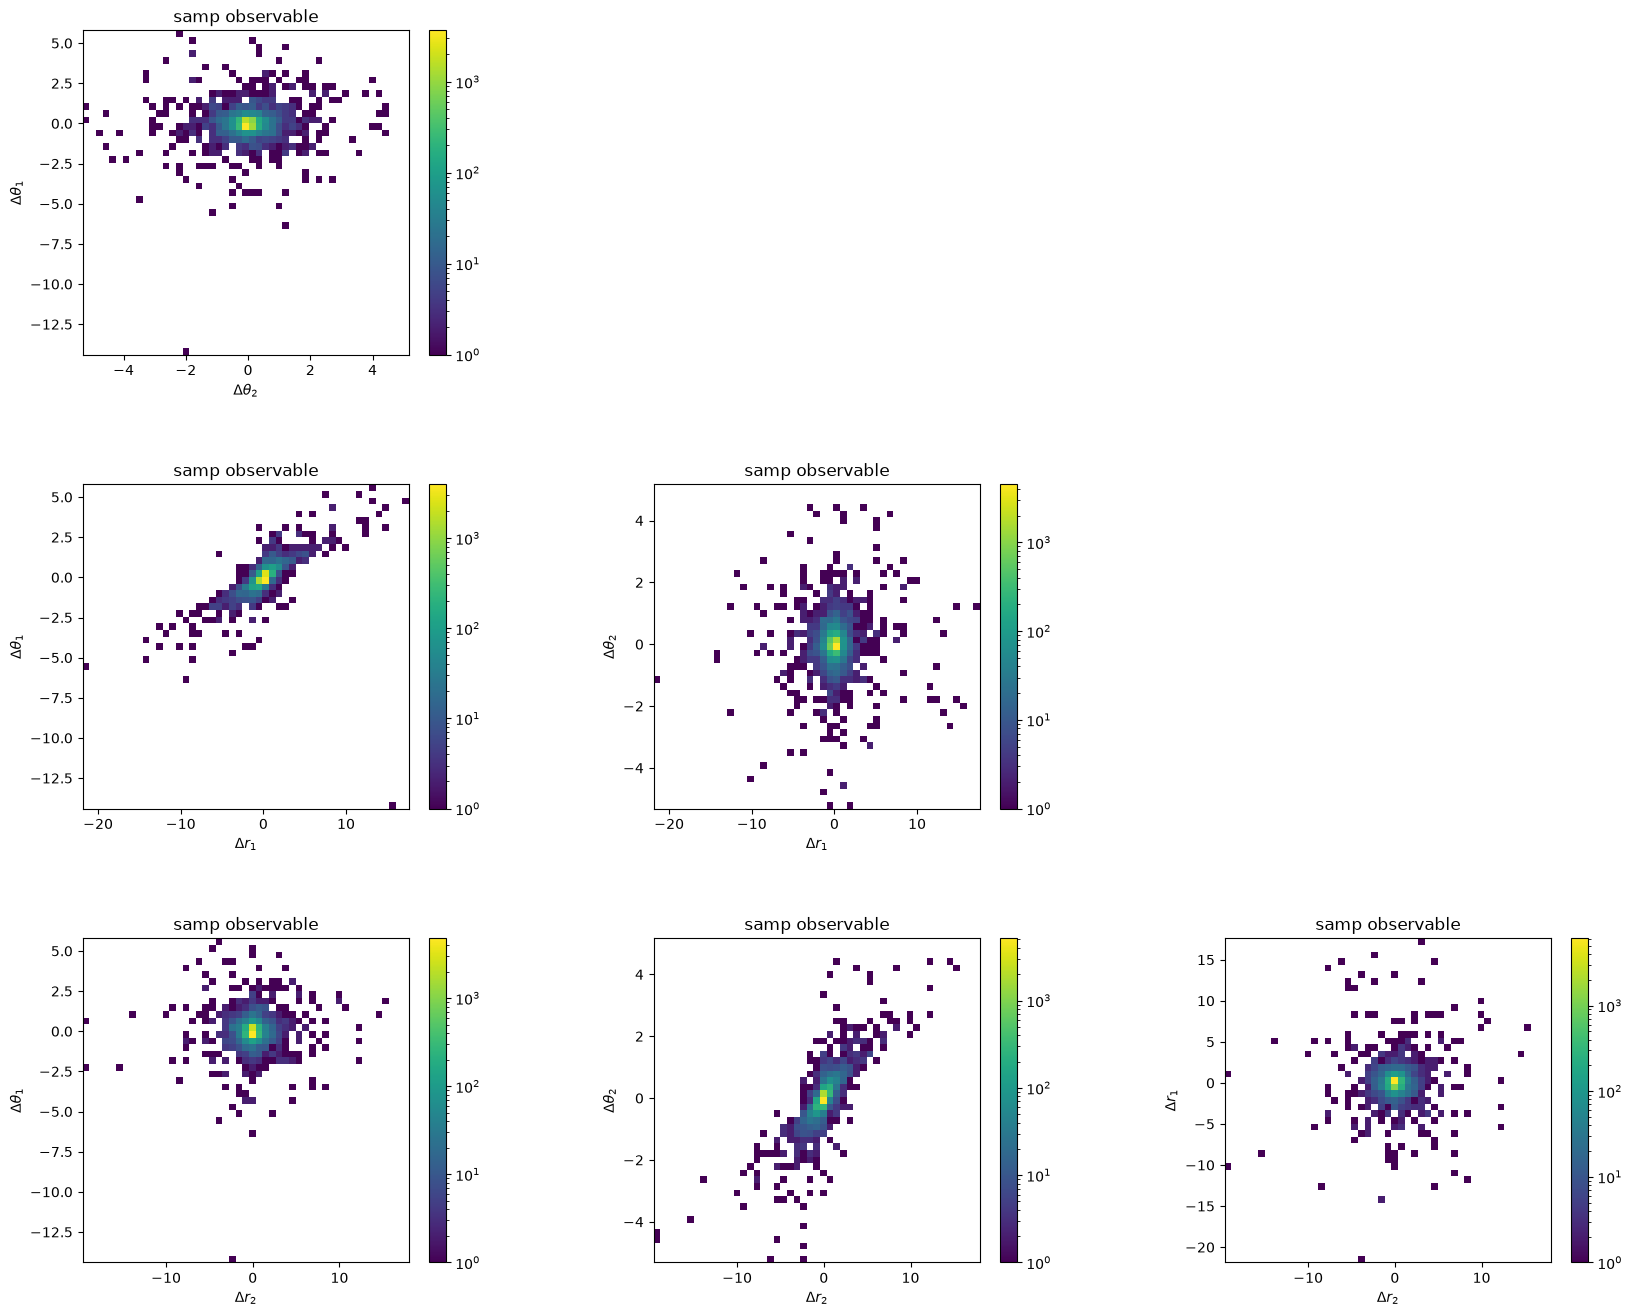

Propagating batch of 5000 for mapper update
Propagation : [====================================================================================================] 100%
Propagation done in 15140 steps, max distance 7.963
Masking 273 out of 5000 events [5.460%]
Values outside [-5,+5] : 0.550%


Log prob:   0%|          | 0/76 [00:00<?, ?it/s]

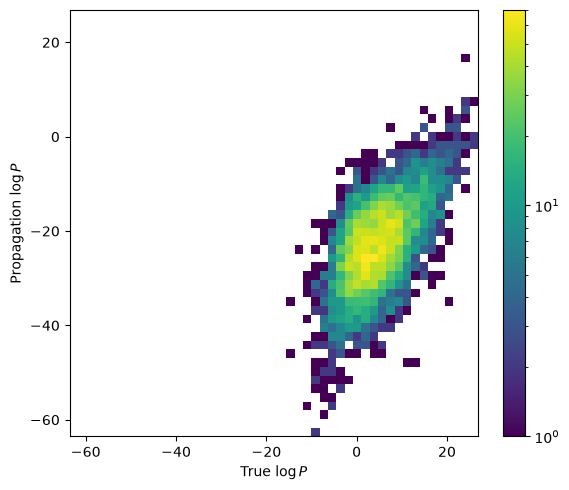

Loss =  4.72394 (sim) - -22.88247 (data) = 27.60641 (total)


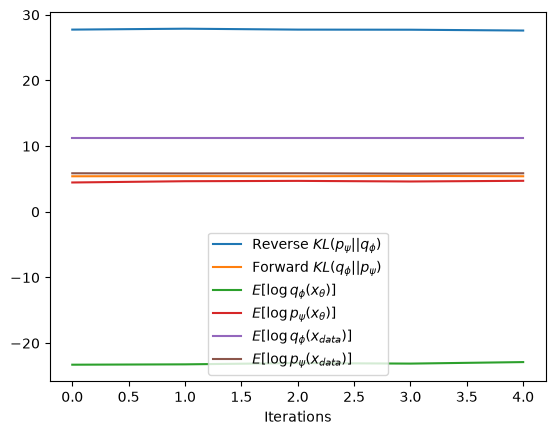

pow creates nans
tensor([nan, nan, nan,  ..., nan, nan, nan], device='cuda:0')
pow creates nans
tensor([nan, nan, nan,  ..., nan, nan, nan], device='cuda:0')
pow creates nans
tensor([nan, nan, nan,  ..., nan, nan, nan], device='cuda:0')
pow creates nans
tensor([nan, nan, nan,  ..., nan, nan, nan], device='cuda:0')
pow creates nans
tensor([nan, nan, nan,  ..., nan, nan, nan], device='cuda:0')
pow creates nans
tensor([nan, nan, nan,  ..., nan, nan, nan], device='cuda:0')


/software/lw23382/Muon_SBI/notebooks/../src/models.py:351: RuntimeWarning: All-NaN slice encountered
  lambda_min = float(np.nanmin(density_plot))
/software/lw23382/Muon_SBI/notebooks/../src/models.py:352: RuntimeWarning: All-NaN slice encountered
  lambda_max = float(np.nanmax(density_plot))


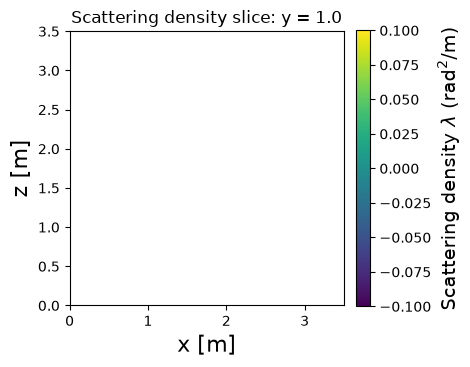

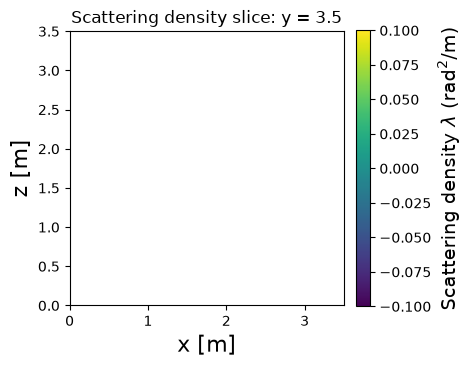

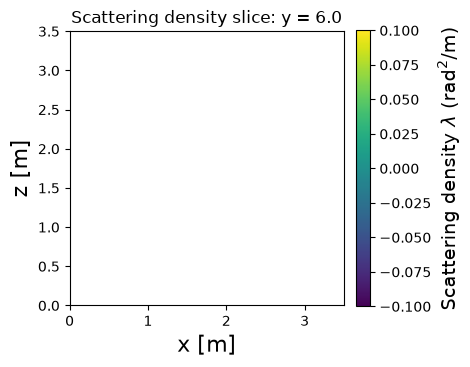

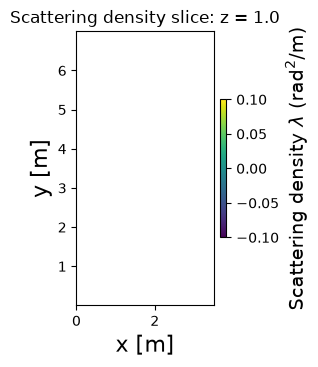

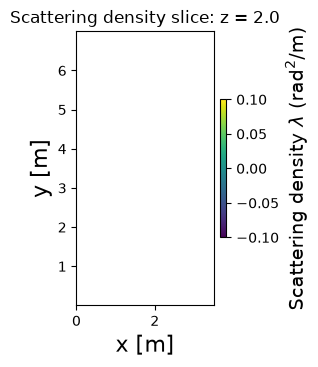

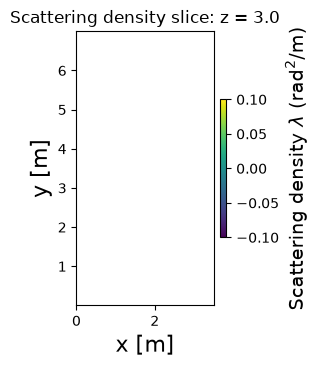

Iteration 6/1000 [ 0.60]%
Propagating simulation dataset with 100000 muons
pow creates nans
tensor([nan, nan, nan,  ..., nan, nan, nan], device='cuda:0')


RuntimeError: There are 100000 nan lambda values

In [14]:
scheduler.optimize(n_iterations=1000,n_simulations=100000,n_gradients=5000)

In [ ]:
scheduler.callbacks[0].plot(iteration=None)

In [ ]:
scheduler.callbacks[1].plot(iteration=None,mapper=scheduler.mapper)

In [ ]:
fig = mapper.plot_slice(
    direction = 'z',
    value = 2.5,
    low = dataset.low[:2],
    high = dataset.high[:2],
    batch_size = 5000,
    points = 20,
)
plt.show()

fig = mapper.plot_slice(
    direction = 'y',self.propagate(batch_size)
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
)
plt.show()

In [ ]:
fig = mapper.plot_slice(
    direction = 'z',
    value = 2.5,
    low = dataset.low[:2],
    high = dataset.high[:2],
    batch_size = 5000,
    points = 20,
)
plt.show()

fig = mapper.plot_slice(
    direction = 'y',
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
)
plt.show()

In [ ]:
scheduler.run(n_iterations=100,batch_size=256)

In [ ]:
scheduler.surrogate.validate_model(batch_size=1000)

In [ ]:
observables = positions_to_observables(
    ri = ri,
    rf = rf,
    di = di,
    df = df,
    lo = dataset.low,
    hi = dataset.high,
)
observables = torch.stack(observables,dim=1)
conditions = torch.cat([ri,di],dim=1)


In [ ]:
fig = scheduler.compare_observables(observables.detach())
plt.show()